# Smart MCQ Solver Challenge

## Notebook Outline

1. Environment Setup
2. Data Loading
3. Exploratory Data Analysis
4. Model 1 – TF-IDF + LightGBM Learning-to-Rank
5. Model 2 – Fine-tuned DeBERTa
6. Model 3 – Retrieval-Augmented Ranking
7. Model 4 – Weighted Ensemble
8. Results Comparison
9. Conclusion
10. Appendix

# Envirionment Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
!pip install -q transformers datasets accelerate sentencepiece evaluate sentence-transformers faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 84.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 98.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23

In [3]:
from transformers import logging

logging.set_verbosity_warning()   # only important warnings

In [4]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import re
from wordcloud import WordCloud

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold, GroupKFold
from lightgbm import LGBMClassifier, LGBMRanker

from scipy.sparse import hstack
from tqdm import tqdm
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from scipy.special import softmax

import torch

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForMultipleChoice,
    TrainingArguments,
    Trainer,
    set_seed
)

from sklearn.model_selection import train_test_split

import evaluate

from tqdm.auto import tqdm

from sentence_transformers import (
    SentenceTransformer,
    CrossEncoder
)

import faiss

import wandb

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

## Experiment Tracking (Weights & Biases)

In [5]:
PROJECT_NAME = "21f3002441-t22026"

In [6]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("WANDB_TOKEN")

In [7]:
wandb.login(key=secret_value_0)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 21f3002441 (21f3002441-dl-genai-project) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

# Data Importing

In [8]:
train_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')
submission_df = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv')

# Exploratory Data Analysis

In [9]:
train_data = train_df.copy()
test_data = test_df.copy()
submission_data = submission_df.copy()

In [10]:
print("Dataset preview : \n")
train_data.head()

Dataset preview : 



,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [11]:
print(f"Train data size : {train_data.shape}")
print(f"Test data size : {test_data.shape}")

Train data size : (2000, 8)
Test data size : (500, 7)


In [12]:
train_data.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

## Answer Distribution

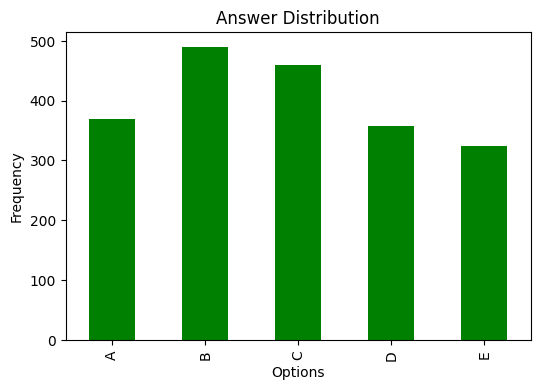

In [13]:
train_data["answer"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(6,4), 
    color='g'
)
plt.title("Answer Distribution")
plt.xlabel("Options")
plt.ylabel("Frequency")
plt.show()

## Prompt Word Count Distribution

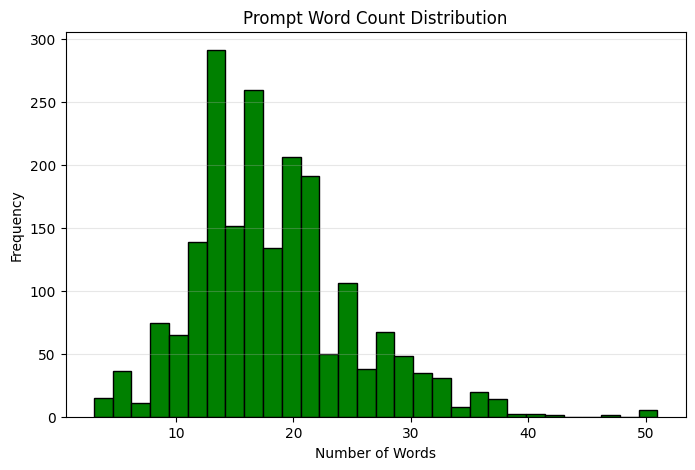

In [14]:
# Calculate prompt length in words
train_data["prompt_word_count"] = (
    train_data["prompt"]
    .astype(str)
    .str.split()
    .str.len()
)

plt.figure(figsize=(8,5))
plt.hist(train_data["prompt_word_count"], bins=30,color='g', edgecolor="black")
plt.title("Prompt Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.show()

## Option Length Distributions

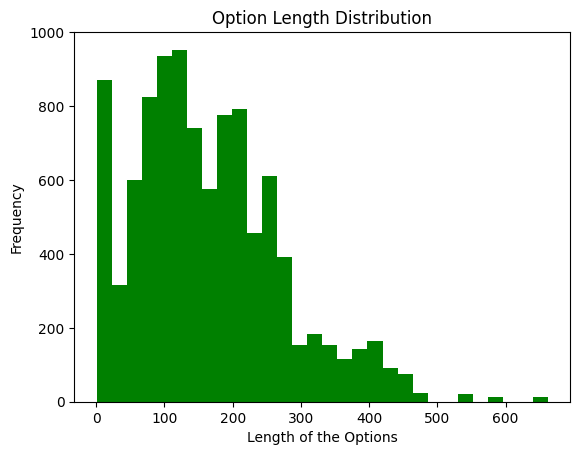

In [15]:
option_lengths = []

for col in ["A","B","C","D","E"]:
    option_lengths.extend(train_df[col].str.len())

plt.hist(option_lengths, bins=30, color='g')
plt.title("Option Length Distribution")
plt.xlabel("Length of the Options")
plt.ylabel("Frequency")
plt.show()

## Prompt vs Option Length Comparison

### 1. Comparison using Box Plot

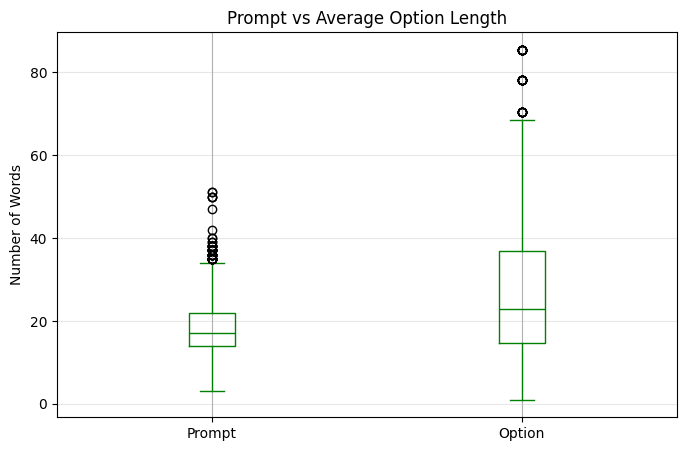

In [16]:
# Prompt word count
train_data["prompt_words"] = (
    train_df["prompt"]
    .astype(str)
    .str.split()
    .str.len()
)

# Average option word count
train_data["option_words"] = (
    train_data[["A","B","C","D","E"]]
    .astype(str)
    .apply(lambda col: col.str.split().str.len())
    .mean(axis=1)
)

comparison = pd.DataFrame({
    "Prompt": train_data["prompt_words"],
    "Option": train_data["option_words"]
})

plt.figure(figsize=(8,5))
comparison.boxplot(color='g')
plt.ylabel("Number of Words")
plt.title("Prompt vs Average Option Length")
plt.grid(axis="y", alpha=0.3)
plt.show()

### 2. Comparison using Distribution Plot

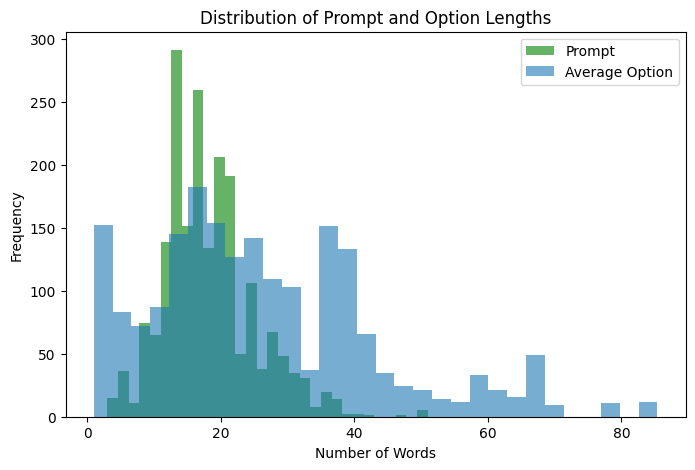

In [17]:
plt.figure(figsize=(8,5))

plt.hist(
    train_data["prompt_words"],
    bins=30,
    alpha=0.6,
    label="Prompt",
    color='g'
)

plt.hist(
    train_data["option_words"],
    bins=30,
    alpha=0.6,
    label="Average Option"
)

plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.title("Distribution of Prompt and Option Lengths")
plt.legend()
plt.show()

## Most Frequent Words in Prompts

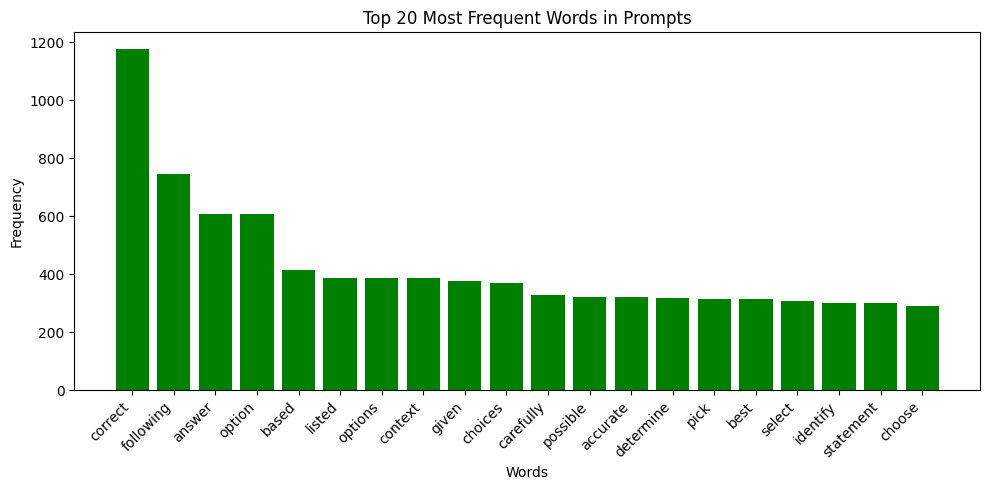

In [18]:
# Combine all prompts
text = " ".join(train_data["prompt"].astype(str))

# Lowercase and tokenize
words = re.findall(r"\b[a-zA-Z]+\b", text.lower())

# Remove stopwords
words = [w for w in words if w not in ENGLISH_STOP_WORDS]

# Count frequencies
word_counts = Counter(words)

# Top 20 words
top_words = word_counts.most_common(20)

# Plot
words, counts = zip(*top_words)

plt.figure(figsize=(10,5))
plt.bar(words, counts, color='g')
plt.xticks(rotation=45, ha="right")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.title("Top 20 Most Frequent Words in Prompts")
plt.tight_layout()
plt.show()

### Word Cloud Visualization

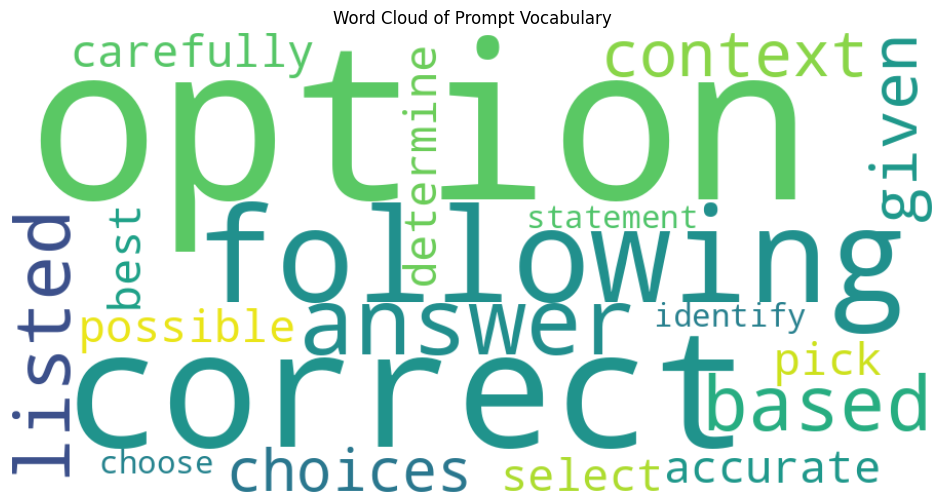

In [19]:
wordcloud = WordCloud(
    width=900,
    height=450,
    background_color="white"
).generate(" ".join(words))

plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Prompt Vocabulary")
plt.show()

# Model 1 - TF-IDF + LightGBM Learning-to-Rank

## Preprocessing

In [20]:
def clean_text(text):
    text = str(text)
    text = text.lower()
    text = text.replace("\n"," ")
    text = " ".join(text.split())
    return text

In [21]:
for col in ["prompt","A","B","C","D","E"]:
    train_data[col] = train_data[col].fillna("").apply(clean_text)
    test_data[col] = test_data[col].fillna("").apply(clean_text)

## Convert MCQ into Ranking Format

In [22]:
options = ["A","B","C","D","E"]

train_rows = []

for _, row in tqdm(train_data.iterrows(), total=len(train_data)):
    
    correct = row["answer"]
    
    for op in options:
        
        train_rows.append({
            "id": row["id"],
            "prompt": row["prompt"],
            "option": row[op],
            "option_label": op,
            "label": int(op == correct)
        })

train_long = pd.DataFrame(train_rows)

print(train_long.shape)

  0%|          | 0/2000 [00:00<?, ?it/s]

(10000, 5)


## Test Ranking Format

In [23]:
test_rows = []

for _, row in tqdm(test_data.iterrows(), total=len(test_data)):
    
    for op in options:
        
        test_rows.append({
            "id": row["id"],
            "option_label": op,
            "prompt": row["prompt"],
            "option": row[op]
        })

test_long = pd.DataFrame(test_rows)

  0%|          | 0/500 [00:00<?, ?it/s]

## Create Additional Features

### Length Features

In [24]:
for df in [train_long, test_long]:
    df["prompt_len"] = df["prompt"].str.len()
    df["option_len"] = df["option"].str.len()
    df["prompt_words"] = df["prompt"].str.split().str.len()
    df["option_words"] = df["option"].str.split().str.len()

In [25]:
num_cols = [
    "prompt_len",
    "option_len",
    "prompt_words",
    "option_words"
]

### Word Overlap and Similarity Feature

In [26]:
def overlap_count(q, a):
    
    q_words = set(q.split())
    a_words = set(a.split())
    
    return len(q_words & a_words)
def overlap_ratio(q, a):

    q_words = set(q.split())
    a_words = set(a.split())

    if len(q_words) == 0:
        return 0

    return len(q_words & a_words) / len(q_words)

In [27]:
for df in [train_long, test_long]:

    df["overlap"] = [
        overlap_count(q, a)
        for q, a in zip(df["prompt"], df["option"])
    ]
    df["overlap_ratio"] = [
    overlap_ratio(q, a)
    for q, a in zip(df["prompt"], df["option"])
    ]

## TF-IDF Feature Engineering

In [28]:
train_text = (
    train_long["prompt"] +
    " [SEP] " +
    train_long["option"]
)

test_text = (
    test_long["prompt"] +
    " [SEP] " +
    test_long["option"]
)

In [29]:
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1,2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    stop_words="english"
)

In [30]:
char_vec = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3,6),
    min_df=2,
    max_features=30000
)

In [31]:
X_char_train = char_vec.fit_transform(train_text)
X_char_test = char_vec.transform(test_text)

In [32]:
X_word_train = tfidf.fit_transform(train_text)

X_word_test = tfidf.transform(test_text)

### Add Cosine Similarity

In [33]:
train_prompt_vec = tfidf.transform(train_long["prompt"])
train_option_vec = tfidf.transform(train_long["option"])

test_prompt_vec = tfidf.transform(test_long["prompt"])
test_option_vec = tfidf.transform(test_long["option"])

In [34]:
train_long["cosine_sim"] = [
    cosine_similarity(
        train_prompt_vec[i],
        train_option_vec[i]
    )[0][0]
    for i in range(len(train_long))
]

test_long["cosine_sim"] = [
    cosine_similarity(
        test_prompt_vec[i],
        test_option_vec[i]
    )[0][0]
    for i in range(len(test_long))
]

In [35]:
num_cols.extend([
    "overlap",
    "overlap_ratio",
    "cosine_sim"
])

In [36]:
num_cols

['prompt_len',
 'option_len',
 'prompt_words',
 'option_words',
 'overlap',
 'overlap_ratio',
 'cosine_sim']

In [37]:
question_ids = train_long["id"]

In [38]:
X_num_train = csr_matrix(
    train_long[num_cols].values.astype(np.float32)
)

X_num_test = csr_matrix(
    test_long[num_cols].values.astype(np.float32)
)

In [39]:
X_train = hstack([
    X_word_train,
    X_char_train,
    X_num_train
]).tocsr()

X_test = hstack([
    X_word_test,
    X_char_test,
    X_num_test
]).tocsr()

In [40]:
print(X_word_train.shape)
print(X_char_train.shape)
print(X_num_train.shape)
print(X_train.shape)

(10000, 11244)
(10000, 30000)
(10000, 7)
(10000, 41251)


In [41]:
train_long[num_cols].isnull().sum()

prompt_len       0
option_len       0
prompt_words     0
option_words     0
overlap          0
overlap_ratio    0
cosine_sim       0
dtype: int64

In [42]:
y = train_long["label"]

## LightGBM

In [43]:
def map3_score(df):

    scores = []

    for _, g in df.groupby("id"):

        pred = (
            g.sort_values(
                "oof_pred",
                ascending=False
            )["option_label"]
            .tolist()[:3]
        )

        true = g.loc[
            g["label"] == 1,
            "option_label"
        ].iloc[0]

        if true == pred[0]:
            scores.append(1.0)

        elif true == pred[1]:
            scores.append(0.5)

        elif true == pred[2]:
            scores.append(1/3)

        else:
            scores.append(0)

    return np.mean(scores)

### LGBMClassifier

In [44]:
lgb_params = {
    "n_estimators":1500,
    "learning_rate":0.03,
    "num_leaves":127,
    "subsample":0.8,
    "colsample_bytree":0.8,
    "objective":"binary",
    "metric":"auc",
    "verbosity":-1,
    "random_state":42
}

#### Initialize Wandb for Model 1 - Classifier

In [45]:
run = wandb.init(
    entity="21f3002441-dl-genai-project",
    project=PROJECT_NAME,
    name="Model1_LGBMClassifier_Baseline",
    tags=[
        "Model1",
        "Baseline",
        "TFIDF",
        "LightGBM"
    ],
    config=lgb_params
)

wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260724_070435-6oz2kvh2
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run Model1_LGBMClassifier_Baseline
wandb: ⭐️ View project at https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026
wandb: 🚀 View run at https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026/runs/6oz2kvh2


### Train

In [46]:
gkf = GroupKFold(n_splits=5)

oof = np.zeros(len(train_long))
test_preds = np.zeros(len(test_long))

groups = train_long["id"]

acc_scores = []
f1_scores = []
auc_scores = []
map_scores = []

for fold, (tr_idx, val_idx) in enumerate(
    gkf.split(X_train, y, groups)
):

    print(f"\n========== Fold {fold+1} ==========")

    model = LGBMClassifier(**lgb_params)

    model.fit(
        X_train[tr_idx],
        y.iloc[tr_idx]
    )

    # Validation probabilities
    val_prob = model.predict_proba(
        X_train[val_idx]
    )[:, 1]

    oof[val_idx] = val_prob
    
    fold_df = train_long.iloc[val_idx].copy()
    fold_df["oof_pred"] = val_prob
    
    fold_map = map3_score(fold_df)

    map_scores.append(fold_map)
    
    # Binary predictions
    val_pred = (val_prob >= 0.5).astype(int)

    # Metrics
    acc = accuracy_score(y.iloc[val_idx], val_pred)
    f1 = f1_score(y.iloc[val_idx], val_pred)
    auc = roc_auc_score(y.iloc[val_idx], val_prob)

    acc_scores.append(acc)
    f1_scores.append(f1)
    auc_scores.append(auc)

    print(
        f"Accuracy: {acc:.4f} | "
        f"F1: {f1:.4f} | "
        f"AUC: {auc:.4f}"
    )

    # Log fold metrics
    wandb.log({
        "fold": fold + 1,
        "fold_accuracy": acc,
        "fold_f1": f1,
        "fold_auc": auc,
        "fold_map3": fold_map
    })

    # Test predictions
    test_preds += (
        model.predict_proba(X_test)[:, 1] / gkf.n_splits
    )


========== Fold 1 ==========
Accuracy: 0.9875 | F1: 0.9684 | AUC: 0.9990

========== Fold 2 ==========
Accuracy: 0.9910 | F1: 0.9772 | AUC: 0.9996

========== Fold 3 ==========
Accuracy: 0.9905 | F1: 0.9758 | AUC: 0.9995

========== Fold 4 ==========
Accuracy: 0.9870 | F1: 0.9670 | AUC: 0.9992

========== Fold 5 ==========
Accuracy: 0.9920 | F1: 0.9798 | AUC: 0.9995


### Logging to Wandb

In [47]:
train_long["oof_pred"] = oof
cv_score = map3_score(train_long)

# Log overall CV metrics
wandb.log({
    "cv_accuracy": np.mean(acc_scores),
    "cv_f1": np.mean(f1_scores),
    "cv_auc": np.mean(auc_scores),
    "cv_map3": cv_score,
    "mean_fold_map3": np.mean(map_scores)
})

wandb.summary["Primary Metric"] = cv_score
wandb.summary["Metric Name"] = "CV MAP@3"
wandb.summary["Evaluation Protocol"] = "5-Fold GroupKFold CV"
wandb.summary["CV MAP@3"] = cv_score
wandb.summary["Mean Fold MAP@3"] = np.mean(map_scores)
wandb.summary["Mean Accuracy"] = np.mean(acc_scores)
wandb.summary["Mean F1"] = np.mean(f1_scores)
wandb.summary["Mean ROC AUC"] = np.mean(auc_scores)
wandb.summary["Model"] = "LightGBM Classifier"


print("\nCross Validation Results")
print(f"Mean Accuracy : {np.mean(acc_scores):.4f}")
print(f"Mean F1 Score : {np.mean(f1_scores):.4f}")
print(f"Mean ROC-AUC  : {np.mean(auc_scores):.4f}")
print(f"CV MAP@3 : {cv_score:.6f}")

run.finish()

wandb: updating run metadata



Cross Validation Results
Mean Accuracy : 0.9896
Mean F1 Score : 0.9737
Mean ROC-AUC  : 0.9994
CV MAP@3 : 0.990000


wandb: uploading history steps 4-5, summary, console lines 14-20
wandb: 
wandb: Run history:
wandb:    cv_accuracy ▁
wandb:         cv_auc ▁
wandb:          cv_f1 ▁
wandb:        cv_map3 ▁
wandb:           fold ▁▃▅▆█
wandb:  fold_accuracy ▂▇▆▁█
wandb:       fold_auc ▁█▆▃▇
wandb:        fold_f1 ▂▇▆▁█
wandb:      fold_map3 ▁▇▇▂█
wandb: mean_fold_map3 ▁
wandb: 
wandb: Run summary:
wandb:            CV MAP@3 0.99
wandb: Evaluation Protocol 5-Fold GroupKFold CV...
wandb:       Mean Accuracy 0.9896
wandb:             Mean F1 0.97365
wandb:     Mean Fold MAP@3 0.99
wandb:        Mean ROC AUC 0.99936
wandb:         Metric Name CV MAP@3
wandb:               Model LightGBM Classifier
wandb:      Primary Metric 0.99
wandb:         cv_accuracy 0.9896
wandb:                  +9 ...
wandb: 
wandb: 🚀 View run Model1_LGBMClassifier_Baseline at: https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026/runs/6oz2kvh2
wandb: ⭐️ View project at: https://wandb.ai/21f3002441-dl-genai-project/21f3002441

### Prediction and Submission Data Preparation

In [48]:
test_long["score"] = test_preds

submission_rows = []

for qid, group in test_long.groupby("id"):
    
    ranked = group.sort_values(
        "score",
        ascending=False
    )
    
    top3 = ranked["option_label"].head(3).tolist()
    
    submission_rows.append({
        "id": qid,
        "prediction": " ".join(top3)
    })

submission = pd.DataFrame(submission_rows)
submission.head()

,id,prediction
0,1,A E B
1,2,B D A
2,3,B D E
3,4,E C D
4,5,C D A


In [49]:
submission.to_csv(
    "submission.csv",
    index=False
)

### LGBMRanker

In [50]:
ranker_params = {
    "objective": "lambdarank",
    "metric": "ndcg",
    "n_estimators": 500,
    "learning_rate": 0.05,
    "num_leaves": 63,
    "force_col_wise": True,
    "verbosity": -1,
    "random_state": 42,
    "n_jobs": -1
}

#### Initialize Wandb for Model 1 - Ranker

In [51]:
run = wandb.init(
    entity="21f3002441-dl-genai-project",
    project=PROJECT_NAME,
    name="Model1_LGBMRanker_Improved",
    tags=[
        "Model1",
        "Ranker",
        "LightGBM",
        "LearningToRank",
        "TFIDF"
    ],
    config=ranker_params
)

wandb: setting up run kjssn5bt
wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260724_075302-kjssn5bt
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run Model1_LGBMRanker_Improved
wandb: ⭐️ View project at https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026
wandb: 🚀 View run at https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026/runs/kjssn5bt


### Training

In [52]:
gkf = GroupKFold(n_splits=5)

groups = train_long["id"]

oof = np.zeros(len(train_long))
test_preds = np.zeros(len(test_long))

fold_scores = []

for fold, (tr_idx, val_idx) in enumerate(
    gkf.split(X_train, y, groups)
):

    print(f"\n========== Fold {fold+1} ==========")

    ranker = LGBMRanker(**ranker_params)

    # Group sizes

    train_groups = (
        train_long.iloc[tr_idx]
        .groupby("id")
        .size()
        .values
    )

    valid_groups = (
        train_long.iloc[val_idx]
        .groupby("id")
        .size()
        .values
    )

    # Train

    ranker.fit(
        X_train[tr_idx],
        y.iloc[tr_idx],
        group=train_groups,
        eval_set=[(X_train[val_idx], y.iloc[val_idx])],
        eval_group=[valid_groups]
    )

    # Validation Predictions

    val_pred = ranker.predict(
        X_train[val_idx]
    )

    oof[val_idx] = val_pred

    # Fold MAP@3

    fold_df = train_long.iloc[val_idx].copy()
    fold_df["oof_pred"] = val_pred

    fold_map = map3_score(fold_df)

    fold_scores.append(fold_map)

    print(f"Fold MAP@3 : {fold_map:.6f}")

    wandb.log({
    "fold": fold + 1,
    "fold_map3": fold_map
    })

    # Test Prediction

    test_preds += (
        ranker.predict(X_test) / gkf.n_splits
    )


========== Fold 1 ==========
Fold MAP@3 : 0.985000

========== Fold 2 ==========
Fold MAP@3 : 0.992500

========== Fold 3 ==========
Fold MAP@3 : 0.993750

========== Fold 4 ==========
Fold MAP@3 : 0.989167

========== Fold 5 ==========
Fold MAP@3 : 0.994583


In [53]:
# Overall CV Score
train_long["oof_pred"] = oof

cv_score = map3_score(train_long)

print("\nCross Validation Results")
print(f"Mean Fold MAP@3 : {np.mean(fold_scores):.6f}")
print(f"CV MAP@3        : {cv_score:.6f}")


# Log Final Metrics

wandb.log({
    "mean_fold_map3": np.mean(fold_scores),
    "cv_map3": cv_score
})

# Summary

wandb.summary["Primary Metric"] = cv_score
wandb.summary["Metric Name"] = "CV MAP@3"
wandb.summary["Evaluation Protocol"] = "5-Fold GroupKFold CV"
wandb.summary["CV MAP@3"] = cv_score
wandb.summary["Mean Fold MAP@3"] = np.mean(fold_scores)
wandb.summary["Model"] = "LightGBM Ranker"


Cross Validation Results
Mean Fold MAP@3 : 0.991000
CV MAP@3        : 0.991000


## Preparing Prediction Probabilities for Ensembling

In [54]:
# Validation probabilities
n_train_questions = len(train_df)

model1_oof_prob = np.zeros((n_train_questions, 5))

for i in range(n_train_questions):

    scores = oof[i*5:(i+1)*5]

    model1_oof_prob[i] = softmax(scores)

print(model1_oof_prob.shape)

# Test probabilities
n_test_questions = len(test_df)

model1_test_prob = np.zeros((n_test_questions,5))

for i in range(n_test_questions):

    scores = test_preds[i*5:(i+1)*5]

    model1_test_prob[i]=softmax(scores)

print(model1_test_prob.shape)

# Save the artficats

np.save("model1_oof_prob.npy",model1_oof_prob)

np.save("model1_test_prob.npy",model1_test_prob)

# Log into W&B
wandb.save("model1_oof_prob.npy")
wandb.save("model1_test_prob.npy")

wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.
wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.


(2000, 5)
(500, 5)


['/kaggle/working/wandb/run-20260724_075302-kjssn5bt/files/model1_test_prob.npy']

## Save the artifacts

In [55]:
import joblib

joblib.dump(
    ranker,
    "lgbm_ranker.pkl"
)

joblib.dump(
    tfidf,
    "word_tfidf.pkl"
)

joblib.dump(
    char_vec,
    "char_tfidf.pkl"
)

['char_tfidf.pkl']

## Finish Wandb for Model 1

In [56]:
model_artifact = wandb.Artifact(
    "lgbm_ranker",
    type="model"
)

model_artifact.add_file("lgbm_ranker.pkl")

wandb.log_artifact(model_artifact)

feature_artifact = wandb.Artifact(
    "tfidf_vectorizers",
    type="feature_extractor"
)

feature_artifact.add_file("word_tfidf.pkl")
feature_artifact.add_file("char_tfidf.pkl")

wandb.log_artifact(feature_artifact)

run.finish()

wandb: updating run metadata; uploading artifact lgbm_ranker; uploading artifact tfidf_vectorizers
wandb: uploading artifact lgbm_ranker; uploading artifact tfidf_vectorizers
wandb: uploading artifact tfidf_vectorizers
wandb: uploading output.log
wandb: uploading history steps 4-5, summary, console lines 14-22
wandb: 
wandb: Run history:
wandb:        cv_map3 ▁
wandb:           fold ▁▃▅▆█
wandb:      fold_map3 ▁▆▇▄█
wandb: mean_fold_map3 ▁
wandb: 
wandb: Run summary:
wandb:            CV MAP@3 0.991
wandb: Evaluation Protocol 5-Fold GroupKFold CV...
wandb:     Mean Fold MAP@3 0.991
wandb:         Metric Name CV MAP@3
wandb:               Model LightGBM Ranker
wandb:      Primary Metric 0.991
wandb:             cv_map3 0.991
wandb:                fold 5
wandb:           fold_map3 0.99458
wandb:      mean_fold_map3 0.991
wandb: 
wandb: 🚀 View run Model1_LGBMRanker_Improved at: https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026/runs/kjssn5bt
wandb: ⭐️ View project at: https://

## Evaluation

In [57]:
train_long["oof_pred"] = oof

cv_score = map3_score(train_long)

print(f"CV MAP@3 : {cv_score:.6f}")

CV MAP@3 : 0.991000


In [58]:
example_id = train_long["id"].iloc[0]

display(
    train_long[train_long["id"] == example_id][
        ["option_label", "label", "oof_pred"]
    ].sort_values("oof_pred", ascending=False)
)

,option_label,label,oof_pred
1,B,1,6.359652
2,C,0,-3.568744
0,A,0,-3.946336
4,E,0,-4.441805
3,D,0,-5.361554


## Predictions

In [59]:
test_long["score"] = test_preds

In [60]:
test_long.head()

,id,option_label,prompt,option,prompt_len,option_len,prompt_words,option_words,overlap,overlap_ratio,cosine_sim,score
0,1,A,pick the best possible answer: what is the rel...,"for every eigenstate of one hamiltonian, its p...",144,117,19,17,1,0.058824,0.0,4.808152
1,1,B,pick the best possible answer: what is the rel...,"for every eigenstate of one hamiltonian, its p...",144,117,19,17,0,0.000000,0.0,-4.434247
2,1,C,pick the best possible answer: what is the rel...,"for every eigenstate of one hamiltonian, its p...",144,118,19,17,0,0.000000,0.0,-5.037296
3,1,D,pick the best possible answer: what is the rel...,"for every eigenstate of one hamiltonian, its p...",144,120,19,17,0,0.000000,0.0,-4.975927
4,1,E,pick the best possible answer: what is the rel...,"for every eigenstate of one hamiltonian, its p...",144,116,19,17,0,0.000000,0.0,-4.501600


## Submission Data Preparation for Model 1 - TF-IDF + LightGBM Learning-to-Rank

In [61]:
submission_rows = []

for qid, group in test_long.groupby("id"):
    
    ranked = group.sort_values(
        "score",
        ascending=False
    )
    
    top3 = ranked["option_label"].head(3).tolist()
    
    submission_rows.append({
        "id": qid,
        "prediction": " ".join(top3)
    })

In [62]:
submission = pd.DataFrame(submission_rows)
submission.head()

,id,prediction
0,1,A B E
1,2,B D E
2,3,B D E
3,4,E C D
4,5,C D A


In [63]:
submission.to_csv(
    "submission.csv",
    index=False
)

# Model 2 - DeBERTa

In [64]:
train_data = train_df.copy()
test_data = test_df.copy()

print(train_data.shape)
print(test_data.shape)

(2000, 8)
(500, 7)


In [65]:
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


In [66]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


## Encode Labels

In [67]:
label_map = {
    "A":0,
    "B":1,
    "C":2,
    "D":3,
    "E":4
}

train_data["label"] = train_data["answer"].map(label_map)

## Train-Validation Split

In [68]:
train_part, valid_part = train_test_split(
    train_data,
    test_size=0.2,
    stratify=train_data["label"],
    random_state=42
)

## Convert to Hugging Face Dataset

In [69]:
train_ds = Dataset.from_pandas(train_part)
valid_ds = Dataset.from_pandas(valid_part)

test_ds = Dataset.from_pandas(
    test_data.assign(label=0)
)

## Set Seed

In [70]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
set_seed(SEED)

# Removes GPU kernel non-determinism (small speed cost, worth it here)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## Load DeBERTa Tokenizer

In [71]:
MODEL_NAME = "microsoft/deberta-v3-base"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

In [72]:
MAX_LEN = 256

def preprocess(example):

    first_sentences = [
        example["prompt"]
    ] * 5

    second_sentences = [
        example["A"],
        example["B"],
        example["C"],
        example["D"],
        example["E"]
    ]

    tokenized = tokenizer(
        first_sentences,
        second_sentences,
        truncation=True,
        max_length=MAX_LEN
    )

    tokenized["label"] = example["label"]

    return tokenized

In [73]:
train_ds = train_ds.map(preprocess)
valid_ds = valid_ds.map(preprocess)
test_ds = test_ds.map(preprocess)

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

In [74]:
keep_cols = [
    "input_ids",
    "attention_mask",
    "token_type_ids",
    "label"
]

train_ds = train_ds.remove_columns(
    [c for c in train_ds.column_names if c not in keep_cols]
)

valid_ds = valid_ds.remove_columns(
    [c for c in valid_ds.column_names if c not in keep_cols]
)

test_ds = test_ds.remove_columns(
    [c for c in test_ds.column_names if c not in keep_cols]
)

## Data Collector

In [75]:
from dataclasses import dataclass
from transformers.tokenization_utils_base import PreTrainedTokenizerBase

@dataclass
class DataCollatorForMultipleChoice:

    tokenizer: PreTrainedTokenizerBase

    def __call__(self, features):

        labels = [f.pop("label") for f in features]

        batch_size = len(features)
        num_choices = len(features[0]["input_ids"])

        flattened = [
            [
                {
                    k: v[i]
                    for k, v in feature.items()
                    if k!= 'label'
                }
                for i in range(num_choices)
            ]
            for feature in features
        ]

        flattened = sum(flattened, [])

        batch = self.tokenizer.pad(
            flattened,
            return_tensors="pt"
        )

        batch = {
            k: v.view(
                batch_size,
                num_choices,
                -1
            )
            for k, v in batch.items()
        }
        if "token_type_ids" in batch:
            del batch["token_type_ids"]
        
        batch["labels"] = torch.tensor(labels)

        return batch

## Load Model

In [76]:
model = AutoModelForMultipleChoice.from_pretrained(
    MODEL_NAME,
    dtype = torch.float32
)

pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2ForMultipleChoice LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.dense.weight              

model.safetensors:   0%|          | 0.00/371M [00:00<?, ?B/s]

## Metric

In [77]:
accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    acc = accuracy.compute(predictions=preds, references=labels)["accuracy"]

    option_labels = np.array(["A", "B", "C", "D", "E"])
    top3 = np.argsort(logits, axis=1)[:, ::-1][:, :3]
    scores = []
    for true, pred_idx in zip(labels, top3):
        ranked = option_labels[pred_idx]
        true_label = option_labels[true]
        if ranked[0] == true_label:
            scores.append(1.0)
        elif ranked[1] == true_label:
            scores.append(0.5)
        elif ranked[2] == true_label:
            scores.append(1/3)
        else:
            scores.append(0)
    map3 = float(np.mean(scores))

    return {"accuracy": acc, "map3": map3}

## Initialize Wandb for Model 2

In [78]:
run = wandb.init(
    entity="21f3002441-dl-genai-project",
    project=PROJECT_NAME,
    name="Model2_DeBERTa",
    tags=[
        "Model2",
        "Transformer",
        "DeBERTa",
        "MultipleChoice"
    ],
    config={
        "model": MODEL_NAME,
        "epochs": 4,
        "batch_size": 2,
        "learning_rate": 2e-5,
        "weight_decay": 0.01
    }
)

wandb: setting up run e1pwq388
wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260724_080508-e1pwq388
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run Model2_DeBERTa
wandb: ⭐️ View project at https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026
wandb: 🚀 View run at https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026/runs/e1pwq388


## Log dataset information before training

In [79]:
wandb.log({
    "Training Samples": len(train_ds),
    "Validation Samples": len(valid_ds),
    "Model": MODEL_NAME
})

## Training Arguments

In [80]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="deberta_mcq",

    report_to = "wandb",

    learning_rate=2e-5,

    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,

    gradient_accumulation_steps=2,

    num_train_epochs=6,

    fp16=False,

    eval_strategy="epoch",

    save_strategy="epoch",

    load_best_model_at_end=True,
    
    metric_for_best_model="map3",   
    greater_is_better=True,
    
    logging_steps=25,
    
    weight_decay = 0.01,

    seed = 42,
    data_seed = 42
)

In [81]:
collator = DataCollatorForMultipleChoice(
    tokenizer
)

## Trainer

In [82]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    processing_class=tokenizer,
    data_collator=collator,
    compute_metrics=compute_metrics
)

## Train

In [83]:
trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,Accuracy,Map3
1,6.021436,2.546368,0.560000,0.686667
2,3.757053,1.319084,0.767500,0.846667
3,2.794810,0.888551,0.880000,0.915417
4,2.107523,0.769065,0.905000,0.932083
5,1.760675,0.585489,0.912500,0.925833
6,1.625309,0.576184,0.930000,0.943750


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['deberta.embeddings.LayerNorm.weight', 'deberta.embeddings.LayerNorm.bias', 'deberta.encoder.layer.0.attention.output.LayerNorm.weight', 'deberta.encoder.layer.0.attention.output.LayerNorm.bias', 'deberta.encoder.layer.0.output.LayerNorm.weight', 'deberta.encoder.layer.0.output.LayerNorm.bias', 'deberta.encoder.layer.1.attention.output.LayerNorm.weight', 'deberta.encoder.layer.1.attention.output.LayerNorm.bias', 'deberta.encoder.layer.1.output.LayerNorm.weight', 'deberta.encoder.layer.1.output.LayerNorm.bias', 'deberta.encoder.layer.2.attention.output.LayerNorm.weight', 'deberta.encoder.layer.2.attention.output.LayerNorm.bias', 'deberta.encoder.layer.2.output.LayerNorm.weight', 'deberta.encoder.layer.2.output.LayerNorm.bias', 'deberta.encoder.layer.3.attention.output.LayerNorm.weight', 'deberta.encoder.layer.3.attention.output.LayerNorm.bias', 'deberta.encoder.layer.3.output.LayerNorm.weight', 'deberta.encoder.layer.3.output.Laye

TrainOutput(global_step=600, training_loss=3.2768115234375, metrics={'train_runtime': 795.8416, 'train_samples_per_second': 12.063, 'train_steps_per_second': 0.754, 'total_flos': 2395812058354560.0, 'train_loss': 3.2768115234375, 'epoch': 6.0})

## Validation Evaluation

In [84]:
metrics = trainer.evaluate()

wandb.log(metrics)

print(metrics)

{'eval_loss': 0.5761843323707581, 'eval_accuracy': 0.93, 'eval_map3': 0.94375, 'eval_runtime': 11.2024, 'eval_samples_per_second': 35.707, 'eval_steps_per_second': 4.463, 'epoch': 6.0}


## Compute Validation MAP@3

In [85]:
pred = trainer.predict(valid_ds)

logits = pred.predictions

labels = pred.label_ids

option_labels = np.array(["A", "B", "C", "D", "E"])

top3 = np.argsort(logits, axis=1)[:, ::-1][:, :3]

scores = []

for true, pred_idx in zip(labels, top3):

    ranked = option_labels[pred_idx]
    true_label = option_labels[true]

    if ranked[0] == true_label:
        scores.append(1.0)

    elif ranked[1] == true_label:
        scores.append(0.5)

    elif ranked[2] == true_label:
        scores.append(1/3)

    else:
        scores.append(0)

map3 = np.mean(scores)

print(f"Validation MAP@3 : {map3:.5f}")

wandb.log({
    "Validation MAP@3": map3
})

wandb.summary["Validation MAP@3"] = map3

Validation MAP@3 : 0.94375


## Save the artifacts

In [86]:
trainer.save_model(
    "/kaggle/working/model2_deberta_v1"
)

tokenizer.save_pretrained(
    "/kaggle/working/model2_deberta_v1"
)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/model2_deberta_v1/tokenizer_config.json',
 '/kaggle/working/model2_deberta_v1/tokenizer.json')

In [87]:
artifact = wandb.Artifact(
    "model2_deberta_v1",
    type="model"
)

artifact.add_dir("/kaggle/working/model2_deberta_v1")

wandb.log_artifact(artifact)

wandb: Adding directory to artifact (/kaggle/working/model2_deberta_v1)... Done. 2.3s


<Artifact model2_deberta_v1>

## Predict Test Logic

In [88]:
preds = trainer.predict(test_ds)

test_logits = preds.predictions

np.save(
    "/kaggle/working/deberta_logits_v1.npy",
    test_logits
)

wandb: WARNING Artifact "model2_deberta_v1" already exists with the same content. No new version will be created.


## Preparing Prediction Probabilities for Ensembling

In [89]:
# Validation Probabilities
model2_oof_prob = softmax(logits, axis=1)

print(model2_oof_prob.shape)

np.save("model2_oof_prob.npy", model2_oof_prob)

# Test Probabilities

model2_test_prob = softmax(test_logits, axis=1)

np.save("model2_test_prob.npy", model2_test_prob)

# Log into W&B
wandb.save("model2_oof_prob.npy")
wandb.save("model2_test_prob.npy")

wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.
wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.


(400, 5)


['/kaggle/working/wandb/run-20260724_080508-e1pwq388/files/model2_test_prob.npy']

## Convert Logits to Top-3

In [90]:
labels = np.array(
    ["A","B","C","D","E"]
)

top3_predictions = []

for row in test_logits:

    idx = np.argsort(row)[::-1][:3]

    top3_predictions.append(
        " ".join(labels[idx])
    )

## Finish Wandb for Model 2

In [91]:
wandb.summary["Primary Metric"] = map3
wandb.summary["Metric Name"] = "Validation MAP@3"
wandb.summary["Evaluation Protocol"] = "Single Validation Split"
wandb.summary["Validation MAP@3"] = map3
wandb.summary["Validation Accuracy"] = metrics["eval_accuracy"]
wandb.summary["Validation Loss"] = metrics["eval_loss"]
wandb.summary["Model"] = "DeBERTa-v3 Multiple Choice"
run.finish()

wandb: updating run metadata
wandb: uploading summary, console lines 7-9
wandb: 
wandb: Run history:
wandb:        Training Samples ▁
wandb:        Validation MAP@3 ▁
wandb:      Validation Samples ▁
wandb:                   epoch ▁
wandb:           eval/accuracy ▁▅▇████
wandb:               eval/loss █▄▂▂▁▁▁
wandb:               eval/map3 ▁▅▇████
wandb:            eval/runtime ▂▁▃▅▄█▂
wandb: eval/samples_per_second ▇█▆▄▅▁▇
wandb:   eval/steps_per_second ▇█▆▄▅▁▆
wandb:                     +17 ...
wandb: 
wandb: Run summary:
wandb: Evaluation Protocol Single Validation Sp...
wandb:         Metric Name Validation MAP@3
wandb:               Model DeBERTa-v3 Multiple ...
wandb:      Primary Metric 0.94375
wandb:    Training Samples 1600
wandb: Validation Accuracy 0.93
wandb:     Validation Loss 0.57618
wandb:    Validation MAP@3 0.94375
wandb:  Validation Samples 400
wandb:               epoch 6
wandb:                 +28 ...
wandb: 
wandb: 🚀 View run Model2_DeBERTa at: https://wandb.ai/21

## Submission Data Preparation for Model 2 - DeBERTa

In [92]:
submission = pd.DataFrame({
    "id": test_df["id"],
    "prediction": top3_predictions
})

submission.to_csv(
    "submission.csv",
    index=False
)

submission.head()

,id,prediction
0,1,A D B
1,2,B C D
2,3,B E D
3,4,E C D
4,5,E B D


# Model 3A - Baseline Retrieval-Augmented Ranking

In [93]:
train_data = train_df.copy()
test_data = test_df.copy()

print(train_data.shape)
print(test_data.shape)

(2000, 8)
(500, 7)


## Create Knowledge Base

In [94]:
knowledge = []

for _,row in train_data.iterrows():

    answer_text = row[row["answer"]]

    text = (
        row["prompt"]
        +
        " "
        +
        answer_text
    )

    knowledge.append(text)


len(knowledge)

2000

In [95]:
TOP_K = 5

## Initialize Wandb for Model 3 - Baseline

In [96]:
run = wandb.init(
    entity="21f3002441-dl-genai-project",
    project=PROJECT_NAME,
    name="Model3_RAG_Baseline",
    tags=[
        "Model3",
        "RAG",
        "Baseline",
        "Retriever"
    ],
    config={
        "retriever": "all-MiniLM-L6-v2",
        "reranker": "cross-encoder/ms-marco-MiniLM-L-6-v2",
        "top_k": TOP_K,
        "embedding_model": "SentenceTransformer"
    }
)

wandb: setting up run 2zb6kq24
wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260724_081913-2zb6kq24
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run Model3_RAG_Baseline
wandb: ⭐️ View project at https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026
wandb: 🚀 View run at https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026/runs/2zb6kq24


In [97]:
wandb.log({
    "Knowledge Base Size": len(knowledge),
    "Training Questions": len(train_data),
    "Test Questions": len(test_data)
})

## Load Retriever Model

In [98]:
retriever = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

retriever = retriever.to("cuda")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (3 outputs left out)

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## Encode Knowledge

In [99]:
knowledge_embeddings = retriever.encode(
    knowledge,
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True
)

print(knowledge_embeddings.shape)

Batches:   0%|          | 0/32 [00:00<?, ?it/s]

(2000, 384)


In [100]:
wandb.log({
    "Embedding Dimension": knowledge_embeddings.shape[1]
})

## Build FAISS Vector DB

In [101]:
dimension = knowledge_embeddings.shape[1]

index = faiss.IndexFlatIP(dimension)

index.add(knowledge_embeddings)

## Retrieve Context

In [102]:
def retrieve_context(
    question,
    top_k=TOP_K
):

    q_emb = retriever.encode(
        [question],
        normalize_embeddings=True
    )

    scores, ids = index.search(
        q_emb,
        top_k
    )

    contexts = [
        knowledge[i]
        for i in ids[0]
    ]

    return " ".join(contexts)

In [103]:
# Test Case
retrieve_context(
    test_data.prompt.iloc[0]
)

'Pick the best possible answer: What is the relationship between the Hamiltonians and eigenstates in supersymmetric quantum mechanics? carefully. For every eigenstate of one Hamiltonian, its partner Hamiltonian has a corresponding eigenstate with the same energy. Pick the best possible answer: What is the relationship between the Hamiltonians and eigenstates in supersymmetric quantum mechanics? carefully. For every eigenstate of one Hamiltonian, its partner Hamiltonian has a corresponding eigenstate with the same energy. Pick the best possible answer: What is the relationship between the Hamiltonians and eigenstates in supersymmetric quantum mechanics? For every eigenstate of one Hamiltonian, its partner Hamiltonian has a corresponding eigenstate with the same energy. What is the relationship between the Hamiltonians and eigenstates in supersymmetric quantum mechanics? For every eigenstate of one Hamiltonian, its partner Hamiltonian has a corresponding eigenstate with the same energy. 

## Load Cross Encoder

In [104]:
reranker = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2",
    device="cuda"
)

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

## Score MCQ Options

In [105]:
options = [
    "A",
    "B",
    "C",
    "D",
    "E"
]


def predict_question(row):

    context = retrieve_context(
        row["prompt"]
    )

    pairs=[]

    for op in options:

        text = (
            "Context: "
            + context
            +
            " Question: "
            + row["prompt"]
            +
            " Answer: "
            + row[op]
        )

        pairs.append(
            (
                row["prompt"],
                text
            )
        )


    scores = reranker.predict(
        pairs
    )


    order = np.argsort(scores)[::-1]

    prediction = " ".join(
        np.array(options)[order[:3]]
    )

    return prediction

## Generate Submission

In [106]:
predictions=[]

for _,row in tqdm(
    test_data.iterrows(),
    total=len(test_data)
):

    predictions.append(
        predict_question(row)
    )

  0%|          | 0/500 [00:00<?, ?it/s]

In [107]:
wandb.log({
    "Predictions Generated": len(predictions)
})

## Submission Data Preparation for Model 3 - Baseline Retrieval-Augmented Ranking

In [108]:
submission = pd.DataFrame(
    {
        "id":test_data.id,
        "prediction":predictions
    }
)


submission.to_csv(
    "submission.csv",
    index=False
)

## Finish Wandb for Model 3 - Baseline

In [109]:
wandb.summary["Retriever"] = "MiniLM"

wandb.summary["Cross Encoder"] = "MS MARCO MiniLM"

wandb.summary["Knowledge Base Size"] = len(knowledge)

wandb.summary["Model"] = "Baseline RAG"

run.finish()

wandb: updating run metadata
wandb: uploading output.log; uploading wandb-summary.json; uploading config.yaml
wandb: 
wandb: Run history:
wandb:   Embedding Dimension ▁
wandb:   Knowledge Base Size ▁
wandb: Predictions Generated ▁
wandb:        Test Questions ▁
wandb:    Training Questions ▁
wandb: 
wandb: Run summary:
wandb:         Cross Encoder MS MARCO MiniLM
wandb:   Embedding Dimension 384
wandb:   Knowledge Base Size 2000
wandb:                 Model Baseline RAG
wandb: Predictions Generated 500
wandb:             Retriever MiniLM
wandb:        Test Questions 500
wandb:    Training Questions 2000
wandb: 
wandb: 🚀 View run Model3_RAG_Baseline at: https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026/runs/2zb6kq24
wandb: ⭐️ View project at: https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260724_081913-2zb6kq24/logs


### Observation

The baseline RAG pipeline improves contextual understanding by retrieving relevant external passages. However, it directly uses the retrieved context without additional engineered ranking features, leaving room for further improvements.

This motivates the enhanced RAG pipeline presented in Model 3 (Improved).

# Model 3B - Improved Retrieval-Augmented Ranking

In [110]:
train_data = train_df.copy()
test_data = test_df.copy()

## Create Long Format 

In [111]:
options = ["A","B","C","D","E"]

train_rows=[]

for _,row in train_data.iterrows():

    for op in options:

        train_rows.append({
            "id": row["id"],
            "prompt": row["prompt"],
            "option": row[op],
            "option_label": op,
            "label": int(op == row["answer"])
        })


train_long = pd.DataFrame(train_rows)

In [112]:
test_rows=[]

for _,row in test_data.iterrows():

    for op in options:

        test_rows.append({
            "id":row["id"],
            "prompt":row["prompt"],
            "option":row[op],
            "option_label":op
        })


test_long=pd.DataFrame(test_rows)

## Clean Prompt for Retrieval

In [113]:
def clean_prompt(text):

    remove = [
        "Pick the best possible answer:",
        "Determine the correct option:",
        "Choose the correct answer:",
        "Select the most accurate option:",
        "Identify the correct statement:"
    ]

    for r in remove:
        text=text.replace(r,"")

    return text.strip()

## Build Knowledge Base

In [114]:
knowledge=[]


for _,row in train_data.iterrows():

    answer_text = row[row["answer"]]

    doc = (
        clean_prompt(row["prompt"])
        +
        " "
        +
        answer_text
    )

    knowledge.append(doc)


knowledge = list(dict.fromkeys(knowledge))

len(knowledge)

1232

In [115]:
TOP_K = 20 # Defining top K documents to fetch

# Defining ranker parameters
ranker_params = {
    "objective": "lambdarank",
    "metric": "map",
    "learning_rate": 0.03,
    "n_estimators": 500,
    "num_leaves": 31,
    "random_state": 42,
    "verbose": -1
} 


## Initialize Wandb for Model 3 - Improved

In [116]:
run = wandb.init(
    entity="21f3002441-dl-genai-project",
    project=PROJECT_NAME,
    name="Model3_RAG_Improved",
    tags=[
        "Model3",
        "RAG",
        "Improved",
        "LightGBMRanker"
    ],
    config={
        **ranker_params,
        "retriever":"all-MiniLM-L6-v2",
        "cross_encoder":"cross-encoder/ms-marco-MiniLM-L-6-v2",
        "top_k":TOP_K
    }
)

wandb: setting up run zuiotheg
wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260724_081944-zuiotheg
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run Model3_RAG_Improved
wandb: ⭐️ View project at https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026
wandb: 🚀 View run at https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026/runs/zuiotheg


In [117]:
wandb.log({
    "Knowledge Base Size": len(knowledge),
    "Training Questions": train_data.shape[0],
    "Test Questions": test_data.shape[0]
})

## Create FAISS Vector DB

### Retriever

In [118]:
retriever = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device="cuda"
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


### Encode KB:

In [119]:
kb_embeddings = retriever.encode(
    knowledge,
    batch_size=64,
    normalize_embeddings=True,
    show_progress_bar=True
)

Batches:   0%|          | 0/20 [00:00<?, ?it/s]

In [120]:
wandb.log({
    "Embedding Dimension": kb_embeddings.shape[1]
})

### Build FAISS

In [121]:
dim = kb_embeddings.shape[1]

index = faiss.IndexFlatIP(dim)

index.add(kb_embeddings)

## Retrieve Top 20

In [122]:
def retrieve_docs(question, k=TOP_K):

    emb = retriever.encode(
        [clean_prompt(question)],
        normalize_embeddings=True
    )

    scores, ids = index.search(
        emb,
        k
    )

    return [
        knowledge[i]
        for i in ids[0]
    ]

## Cross Encoder Reranking

In [123]:
reranker = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2",
    device="cuda"
)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [124]:
def get_best_context(question):

    docs = retrieve_docs(question)

    pairs = [
        [
            clean_prompt(question),
            doc
        ]
        for doc in docs
    ]

    scores = reranker.predict(pairs)

    best = np.argmax(scores)

    return docs[best]

## Generate Contexts Once

In [125]:
train_context={}

for qid,prompt in tqdm(
    zip(train_data.id, train_data.prompt),
    total=len(train_data)
):

    train_context[qid] = get_best_context(prompt)

  0%|          | 0/2000 [00:00<?, ?it/s]

In [126]:
test_context={}

for qid,prompt in tqdm(
    zip(test_data.id, test_data.prompt),
    total=len(test_data)
):

    test_context[qid] = get_best_context(prompt)

  0%|          | 0/500 [00:00<?, ?it/s]

In [127]:
train_long["context"] = (
    train_long["id"].map(train_context)
)

test_long["context"] = (
    test_long["id"].map(test_context)
)

## Create RAG Text Features

In [128]:
train_text = (
    train_long.context
    +
    " [SEP] "
    +
    train_long.prompt
    +
    " [SEP] "
    +
    train_long.option
)


test_text = (
    test_long.context
    +
    " [SEP] "
    +
    test_long.prompt
    +
    " [SEP] "
    +
    test_long.option
)

## TF-IDF + Char Features

In [129]:
word_vec = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1,2)
)

char_vec = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3,5),
    max_features=15000
)

X_word_train = word_vec.fit_transform(train_text)
X_word_test = word_vec.transform(test_text)


X_char_train = char_vec.fit_transform(train_text)
X_char_test = char_vec.transform(test_text)

## Add RAG Numerical Features

In [130]:
def overlap(a,b):

    a=set(a.lower().split())
    b=set(b.lower().split())

    return len(a & b)

In [131]:
for df in [train_long,test_long]:

    df["context_overlap"] = df.apply(
        lambda x:
        overlap(
            x.context,
            x.option
        ),
        axis=1
    )


    df["option_len"] = (
        df.option.str.len()
    )

In [132]:
num_cols=[
    "context_overlap",
    "option_len"
]

X_num_train=csr_matrix(
    train_long[num_cols]
)

X_num_test=csr_matrix(
    test_long[num_cols]
)

## Final Matrix

In [133]:
X_train=hstack([
    X_word_train,
    X_char_train,
    X_num_train
]).tocsr()


X_test=hstack([
    X_word_test,
    X_char_test,
    X_num_test
]).tocsr()

## Train LGBMRanker

In [134]:
def map3_score(df):

    scores = []

    for _, g in df.groupby("id"):

        pred = (
            g.sort_values(
                "oof_pred",
                ascending=False
            )["option_label"]
            .tolist()[:3]
        )

        true = g.loc[
            g["label"] == 1,
            "option_label"
        ].iloc[0]

        if true == pred[0]:
            scores.append(1.0)
        elif true == pred[1]:
            scores.append(0.5)
        elif true == pred[2]:
            scores.append(1/3)
        else:
            scores.append(0.0)

    return np.mean(scores)

In [135]:
groups = train_long.id
y = train_long.label

oof = np.zeros(len(train_long))
test_preds = np.zeros(len(test_long))

gkf = GroupKFold(n_splits=5)

fold_scores = []

for fold, (tr, val) in enumerate(
    gkf.split(X_train, y, groups)
):

    print(f"\n========== Fold {fold+1} ==========")

    model = LGBMRanker(**ranker_params)

    train_group = (
        train_long.iloc[tr]
        .groupby("id")
        .size()
        .values
    )

    model.fit(
        X_train[tr],
        y.iloc[tr],
        group=train_group
    )

    # Validation predictions
    oof[val] = model.predict(X_train[val])

    # Test predictions
    test_preds += model.predict(X_test) / gkf.n_splits

    # Validation MAP@3
    fold_df = train_long.iloc[val].copy()
    fold_df["oof_pred"] = oof[val]

    fold_map = map3_score(fold_df)

    fold_scores.append(fold_map)

    print(f"Fold {fold+1} MAP@3 : {fold_map:.5f}")


    # W&B Fold Logging
    wandb.log({
    "fold": fold + 1,
    "fold_map3": fold_map
    })


========== Fold 1 ==========
Fold 1 MAP@3 : 0.99625

========== Fold 2 ==========
Fold 2 MAP@3 : 0.99875

========== Fold 3 ==========
Fold 3 MAP@3 : 0.99625

========== Fold 4 ==========
Fold 4 MAP@3 : 0.99750

========== Fold 5 ==========
Fold 5 MAP@3 : 0.99875


In [136]:
train_long["oof_pred"] = oof

cv_score = map3_score(train_long)

print("\n========== Cross Validation ==========")
print(f"Mean Fold MAP@3 : {np.mean(fold_scores):.5f}")
print(f"CV MAP@3        : {cv_score:.5f}")

# W&B Final Metrics

wandb.log({
    "mean_fold_map3": np.mean(fold_scores),
    "cv_map3": cv_score
})

# W&B Summary

wandb.summary["Primary Metric"] = cv_score
wandb.summary["Metric Name"] = "CV MAP@3"
wandb.summary["Evaluation Protocol"] = "5-Fold GroupKFold CV"
wandb.summary["CV MAP@3"] = cv_score
wandb.summary["Mean Fold MAP@3"] = np.mean(fold_scores)

wandb.summary["Model"] = "RAG + LightGBM Ranker"
wandb.summary["Retriever"] = "all-MiniLM-L6-v2"
wandb.summary["Cross Encoder"] = "cross-encoder/ms-marco-MiniLM-L-6-v2"
wandb.summary["Top K"] = TOP_K


========== Cross Validation ==========
Mean Fold MAP@3 : 0.99750
CV MAP@3        : 0.99750


## Preparing Prediction Probabilities for Ensembling

In [137]:
# Validation probabilities

n_train_questions = len(train_df)

model3_oof_prob = np.zeros((n_train_questions, 5))

for i in range(n_train_questions):
    scores = oof[i*5:(i+1)*5]
    model3_oof_prob[i] = softmax(scores)

np.save("model3_oof_prob.npy", model3_oof_prob)


# Test probabilities

n_test_questions = len(test_df)

model3_test_prob = np.zeros((n_test_questions, 5))

for i in range(n_test_questions):
    scores = test_preds[i*5:(i+1)*5]
    model3_test_prob[i] = softmax(scores)

np.save("model3_test_prob.npy", model3_test_prob)

# Log into W&B
wandb.save("model3_oof_prob.npy")
wandb.save("model3_test_prob.npy")

wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.
wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.


['/kaggle/working/wandb/run-20260724_081944-zuiotheg/files/model3_test_prob.npy']

## Finish Wandb for Model 3 - Improved

In [138]:
joblib.dump(model, "rag_ranker.pkl")

artifact = wandb.Artifact(
    "rag_ranker",
    type="model"
)

artifact.add_file("rag_ranker.pkl")

wandb.log_artifact(artifact)


# Finish W&B Run

run.finish()

wandb: updating run metadata; uploading artifact rag_ranker
wandb: uploading history steps 6-7, summary, console lines 28-34
wandb: 
wandb: Run history:
wandb: Embedding Dimension ▁
wandb: Knowledge Base Size ▁
wandb:      Test Questions ▁
wandb:  Training Questions ▁
wandb:             cv_map3 ▁
wandb:                fold ▁▃▅▆█
wandb:           fold_map3 ▁█▁▅█
wandb:      mean_fold_map3 ▁
wandb: 
wandb: Run summary:
wandb:            CV MAP@3 0.9975
wandb:       Cross Encoder cross-encoder/ms-mar...
wandb: Embedding Dimension 384
wandb: Evaluation Protocol 5-Fold GroupKFold CV...
wandb: Knowledge Base Size 1232
wandb:     Mean Fold MAP@3 0.9975
wandb:         Metric Name CV MAP@3
wandb:               Model RAG + LightGBM Ranke...
wandb:      Primary Metric 0.9975
wandb:           Retriever all-MiniLM-L6-v2
wandb:                  +7 ...
wandb: 
wandb: 🚀 View run Model3_RAG_Improved at: https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026/runs/zuiotheg
wandb: ⭐️ View project 

## Submission Data Preparation for Model 3 -  Improved Retrieval-Augmented Ranking

In [139]:
test_long["score"]=test_preds

submission = (
    test_long
    .sort_values(
        ["id","score"],
        ascending=[True,False]
    )
    .groupby("id")
    .option_label
    .apply(
        lambda x:
        " ".join(
            x.head(3)
        )
    )
    .reset_index()
)

## Submission for Model 3 - Improved Retrieval-Augmented Ranking

In [140]:
submission.columns=[
    "id",
    "prediction"
]

submission.to_csv(
    "submission.csv",
    index=False
)

# Model 4 - Weighted Ensemble

## Weight Selection for previous models

In [141]:
# Weights selected based on individual model performance
w1 = 0.35      # Model 1
w2 = 0.20      # DeBERTa
w3 = 0.45      # RAG Ranker

ensemble_test_prob = (
    w1 * model1_test_prob +
    w2 * model2_test_prob +
    w3 * model3_test_prob
)

## Initialize Wandb for Model 4

In [142]:
ensemble_params = {
    "ensemble_method": "Weighted Average",
    "model1_weight": 0.35,
    "model2_weight": 0.20,
    "model3_weight": 0.45,
    "model1_score": 0.7550,
    "model2_score": 0.7303,
    "model3_score": 0.7610,
}

run = wandb.init(
    entity="21f3002441-dl-genai-project",
    project=PROJECT_NAME,
    name="Model4_Weighted_Ensemble",
    tags=[
        "Model4",
        "Ensemble",
        "WeightedAverage",
        "FinalModel"
    ],
    config=ensemble_params
)

wandb: setting up run jcfvrry7
wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260724_083321-jcfvrry7
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run Model4_Weighted_Ensemble
wandb: ⭐️ View project at https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026
wandb: 🚀 View run at https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026/runs/jcfvrry7


## Calculationg Top-3 predictions

In [143]:
option_labels = np.array(["A","B","C","D","E"])

top3 = np.argsort(
    ensemble_test_prob,
    axis=1
)[:, ::-1][:,:3]

predictions = [
    " ".join(option_labels[idx])
    for idx in top3
]

## Submission Data Preparation for Model 4 - Weighted Ensemble

In [144]:
submission = pd.DataFrame({
    "id": test_df["id"],
    "prediction": predictions
})

submission.head()

,id,prediction
0,1,A E B
1,2,B C D
2,3,B E D
3,4,E C D
4,5,C E B


In [145]:
submission.to_csv(
    "submission_ensemble.csv",
    index=False
)

## Finish Wandb for Model 4

In [146]:
wandb.log({
    "model1_weight": 0.35,
    "model2_weight": 0.20,
    "model3_weight": 0.45,
})
wandb.save("submission_ensemble.csv")
wandb.finish()

wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.
wandb: updating run metadata; uploading summary
wandb: uploading summary
wandb: uploading data
wandb: 
wandb: Run history:
wandb: model1_weight ▁
wandb: model2_weight ▁
wandb: model3_weight ▁
wandb: 
wandb: Run summary:
wandb: model1_weight 0.35
wandb: model2_weight 0.2
wandb: model3_weight 0.45
wandb: 
wandb: 🚀 View run Model4_Weighted_Ensemble at: https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026/runs/jcfvrry7
wandb: ⭐️ View project at: https://wandb.ai/21f3002441-dl-genai-project/21f3002441-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 1 other file(s)
wandb: Find logs at: ./wandb/run-20260724_083321-jcfvrry7/logs


# Conclusion

Four complementary approaches were explored for solving the Smart MCQ Solver Challenge.

* Model 1 established a strong classical ranking baseline.
* Model 2 leveraged contextual transformer embeddings.
* Model 3 enhanced retrieval with external context and achieved the highest validation MAP@3.
* Model 4 combined all models through weighted ensembling to obtain a competitive Kaggle leaderboard score.

The experiments demonstrate that retrieval augmentation significantly improves ranking performance over classical methods while maintaining efficient inference.

# Appendix

## Milestone 1

In [147]:
import numpy as np
import pandas as pd
import string
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [148]:
train_data = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')

In [149]:
print(f"Columns of the train dataset : {train_data.columns}")

Columns of the train dataset : Index(['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer'], dtype='object')


1. Calculate the frequency distribution of the correct  answer  (A, B, C, D, E) in train.csv. Based on your counts, what is the sum of the occurrences of the most frequent option and the least frequent option?

In [150]:
answer_counts = train_data['answer'].value_counts()
print("Frequency Distribution of the correct answers : \n", answer_counts)

result = answer_counts.max() + answer_counts.min()
print("The sum of the occurrences of the most frequent \
option and the least frequent option:", result)

Frequency Distribution of the correct answers : 
 answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64
The sum of the occurrences of the most frequent option and the least frequent option: 814


2. After converting the prompt column to lowercase and removing all standard punctuation characters (using Python's string.punctuation), split the text by whitespace. What is the total number of unique words (vocabulary size) across the entire cleaned prompt column of train.csv?  

In [151]:
translator = str.maketrans('', '', string.punctuation)

clean_prompts = (
    train_data['prompt']
    .fillna('')
    .str.lower()
    .str.translate(translator)
)

vocab = set()

for text in clean_prompts:
    vocab.update(text.split())

print(f"Total number of unique words (vocabulary size) across \
the entire cleaned prompt column : {len(vocab)}")

Total number of unique words (vocabulary size) across the entire cleaned prompt column : 859


3. Using the cleaned prompt from Row ID 1, filter out the standard English stop words using sklearn.feature_extraction.text.ENGLISH_STOP_WORDS. How many words are left in the prompt for Row ID 1 after filtering?

In [152]:
train_data.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [153]:
display(train_data[train_data['id']==1])
stop_words  = set(ENGLISH_STOP_WORDS)
words = clean_prompts[0].split()

filtered_words = [word for word in words if word not in stop_words]
print(f"Before filtering words : {words}")
print(f"Filtered Words : {filtered_words}")
print(f"Words are left in the prompt for Row ID 1 after filtering : {len(filtered_words)}")

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B


Before filtering words : ['pick', 'the', 'best', 'possible', 'answer', 'what', 'is', 'martin', 'heideggers', 'view', 'on', 'the', 'relationship', 'between', 'time', 'and', 'human', 'existence', 'among', 'the', 'listed', 'options']
Filtered Words : ['pick', 'best', 'possible', 'answer', 'martin', 'heideggers', 'view', 'relationship', 'time', 'human', 'existence', 'listed', 'options']
Words are left in the prompt for Row ID 1 after filtering : 13


4. Fit a default TfidfVectorizer(stop_words='english') on a list containing all the combined text of the prompts and options in train.csv. What is the exact total number of feature columns (vocabulary size) generated by the vectorizer?  

In [154]:
combined_text = (
    train_data['prompt'].fillna('') + ' ' +
    train_data['A'].fillna('') + ' ' +
    train_data['B'].fillna('') + ' ' +
    train_data['C'].fillna('') + ' ' +
    train_data['D'].fillna('') + ' ' +
    train_data['E'].fillna('')
)

vectorizer = TfidfVectorizer(stop_words='english')

X = vectorizer.fit_transform(combined_text)

vocab_size = len(vectorizer.vocabulary_)

print("Vocabulary size:", vocab_size)

Vocabulary size: 2762


5. Using the TF-IDF vectorizer fitted in Question 3, calculate the cosine similarity between the prompt and option A strictly for Row ID 1. What is the resulting similarity score? (Round to 4 decimal places).  

In [155]:
# Row with id = 1
row = train_data[train_data['id'] == 1].iloc[0]

prompt = row['prompt']
option_a = row['A']

# Used the vectorizer already fitted in Q4
prompt_vec = vectorizer.transform([prompt])
option_a_vec = vectorizer.transform([option_a])

similarity = cosine_similarity(prompt_vec, option_a_vec)[0][0]

print(round(similarity, 4))

0.272


6. Expand the logic from Question 4: For every row in train.csv, calculate the cosine similarity between the prompt and each of its 5 options .  Then calculate the percentage of instances where the option with the highest cosine similarity matches the correct answer.

In [156]:
predictions = []

for _, row in train_data.iterrows():

    texts = [row['prompt'], row['A'], row['B'], row['C'], row['D'], row['E']]
    vectors = vectorizer.transform(texts)
    prompt_vec = vectors[0]
    option_vecs = vectors[1:]

    sims = cosine_similarity(prompt_vec, option_vecs)[0]

    predicted = ['A', 'B', 'C', 'D', 'E'][np.argmax(sims)]
    predictions.append(predicted)
   

accuracy = (train_data['answer'] == predictions).mean() * 100

print(f"Accuracy = {accuracy:.2f}%")

Accuracy = 13.55%


7. If the ground truth answer for a question is C, what is the MAP@3 score if a model predicts C A B?  

In [157]:
def find_MAP(truth,pred):
    score = 0
    if truth == pred[0]:
        score = 1.0
    elif truth == pred[1]:
        score = 1/2
    elif truth == pred[2]:
        score = 1/3
    return score

In [158]:
truth = 'C'
pred = ['C','A','B']
print(f"MAP@3 is : {find_MAP(truth,pred)}")

MAP@3 is : 1.0


8. If the ground truth answer for a question is  B, what is the MAP@3 score if a model predicts D B E? 

In [159]:
def find_MAP(truth,pred):
    score = 0
    if truth == pred[0]:
        score = 1.0
    elif truth == pred[1]:
        score = 1/2
    elif truth == pred[2]:
        score = 1/3
    return score

In [160]:
truth = 'B'
pred = ['D','B','E']
print(f"MAP@3 is : {find_MAP(truth,pred)}")

MAP@3 is : 0.5


9. The Majority Class Baseline: Find the most frequent correct answer in the training set (using your data from Q1). Make a static prediction for every single row where that most frequent answer is your 1st guess, followed by the second most frequent, and then the third most frequent. What is the overall MAP@3 score of this "Majority Class" baseline on train.csv?

In [161]:
answer_counts = train_data['answer'].value_counts()

print("Answer Frequency Distribution : ")
print(answer_counts)

top3 = answer_counts.index[:3].tolist()

print("Top 3 Answers : ")
print(top3)

def apk(actual, predicted, k=3):
    predicted = predicted[:k]

    if actual in predicted:
        return 1.0 / (predicted.index(actual) + 1)

    return 0.0

map3 = train_data['answer'].apply(
    lambda x: apk(x, top3)
).mean()

print(f"Majority Class Baseline MAP@3 = {map3:.3f}")

Answer Frequency Distribution : 
answer
B    490
C    459
A    369
D    358
E    324
Name: count, dtype: int64
Top 3 Answers : 
['B', 'C', 'A']
Majority Class Baseline MAP@3 = 0.421


10. The TF-IDF Pipeline: Build a basic pipeline that evaluates every row in train.csv. For each row, calculate the TF-IDF cosine similarity between the prompt and each of the 5 options. Sort these options from highest similarity to lowest to form your top 3 predictions. What is the final average MAP@3 score of this TF-IDF pipeline across the entire training set?  

In [162]:
def apk(actual, predicted, k=3):
    predicted = predicted[:k]

    if actual in predicted:
        return 1.0 / (predicted.index(actual) + 1)

    return 0.0

scores = []

for _, row in train_data.iterrows():

    prompt_vec = vectorizer.transform([row['prompt']])

    similarities = {}

    for option in ['A', 'B', 'C', 'D', 'E']:
        option_vec = vectorizer.transform([row[option]])
        similarities[option] = cosine_similarity(
            prompt_vec,
            option_vec
        )[0][0]

    ranked_options = sorted(
        similarities,
        key=similarities.get,
        reverse=True
    )

    top3 = ranked_options[:3]

    scores.append(
        apk(row['answer'], top3)
    )

map3 = np.mean(scores)

print(f"MAP@3 = {map3:.3f}")

MAP@3 = 0.296


## Milestone 2 

In [163]:
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
from transformers import AutoTokenizer, AutoModel, AutoModelForSeq2SeqLM
from sentence_transformers import SentenceTransformer, util
from transformers import pipeline
import torch

1. Load train.csv using the Hugging Face datasets library (do not use pandas). Use the .map() function to create a new column called combined_text that concatenates the prompt and A columns with a space in between. E.g., prompt_text A_text. What is the exact character length (total number of string characters using Python's len() function, NOT the number of tokens) of the combined_text string for the row at index 51? Note: We follow zero-indexing here.

In [164]:
# Load CSV (no pandas)
dataset = load_dataset("csv", data_files="/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")["train"]
print(dataset)
# Create combined_text = prompt + " " + A
dataset = dataset.map(
    lambda x: {"combined_text": x["prompt"] + " " + x["A"]}
)

# Character length of row at index 51
length = len(dataset[51]["combined_text"])

print(f"Exact character length of the combined_text string \
for the row at index 51 : {length}")

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['id', 'prompt', 'A', 'B', 'C', 'D', 'E', 'answer'],
    num_rows: 2000
})


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Exact character length of the combined_text string for the row at index 51 : 614


2. Initialize the bert-base-uncased tokenizer. Look at the tokenizer's configuration properties: what is the exact total vocabulary size (the maximum number of unique subword tokens the model knows) hardcoded into this tokenizer? 

In [165]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

print(f"Exact total vocabulary size (the maximum number of unique subword \
tokens the model knows) hardcoded into this tokenizer : {tokenizer.vocab_size}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Exact total vocabulary size (the maximum number of unique subword tokens the model knows) hardcoded into this tokenizer : 30522


3. Transformers rely on special tokens to understand sentence boundaries. Using the bert-base-uncased tokenizer from the previous step, extract the exact integer ID assigned to the [SEP] (Separator) token.  

In [166]:
print(f"Exact integer ID assigned to the \
[SEP] : {tokenizer.sep_token_id}")

Exact integer ID assigned to the [SEP] : 102


4. Using the bert-base-uncased tokenizer, tokenize the entire prompt column of the train dataset simultaneously. Set padding='max_length', truncation=True, max_length=128, and return_tensors='pt' (PyTorch tensors). 

What is the exact geometric shape (dimensions) of the resulting input_ids tensor?

In [167]:
encoded = tokenizer(
                   list(dataset["prompt"]),
                   padding='max_length',
                   truncation=True, 
                   max_length=128,
                   return_tensors='pt')
print(f"Exact geometric shape (dimensions) of the resulting \
input_ids tensor : {encoded["input_ids"].shape}")

Exact geometric shape (dimensions) of the resulting input_ids tensor : torch.Size([2000, 128])


5. A standard bert-base-uncased model has a hidden embedding size of 768 dimensions and uses exactly 12 attention heads in each layer. 

    In Transformer architecture, the hidden size is divided equally among the attention heads. What is the exact dimensionality (size) of each individual attention head?  

In [168]:
hidden_embedding_size = 768
attention_heads = 12
# Attention head is divided equally among the attention heads
individual_attention_head_size = hidden_embedding_size//attention_heads
print(f"Eexact dimensionality (size) of each individual \
attention head : {individual_attention_head_size}")

Eexact dimensionality (size) of each individual attention head : 64


6.Load the bert-base-uncased model using AutoModel.from_pretrained(). Tokenize the prompt from row ID 0 using the tokenizer's default settings (do not apply any manual padding or truncation). Pass this tokenized input through the model. Look at the output object. 

What is the exact shape of the last_hidden_state tensor returned? 

Note: We follow zero-indexing here.

In [169]:
# Load tokenizer and model
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
model = AutoModel.from_pretrained("bert-base-uncased")

# Row index 0 prompt
text = dataset[0]["prompt"]

# Default tokenization (no padding/truncation)
inputs = tokenizer(
    text,
    return_tensors="pt"
)

# Forward pass
outputs = model(**inputs)

print(f"Exact shape of the last_hidden_state tensor \
returned : {outputs.last_hidden_state.shape}")

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Exact shape of the last_hidden_state tensor returned : torch.Size([1, 31, 768])


7. Using the last_hidden_state tensor from the previous question, extract the embedding vector representing the [CLS] token (which is always the token at index 0). What is the sum of the first 5 float values in this [CLS] vector? (Round your answer to 4 decimal places).  

In [170]:
cls_embedding = outputs.last_hidden_state[0, 0, :]

# first 5 values
first_5 = cls_embedding[:5]

print(first_5)

# sum and round
answer = round(first_5.sum().item(), 4)

print(f"Sum of the first 5 float values in \
this [CLS] vector : {answer}")

tensor([-0.4677, -0.0754, -0.2019, -0.0071, -0.4480], grad_fn=<SliceBackward0>)
Sum of the first 5 float values in this [CLS] vector : -1.2001


8. Load bert-base-uncased with the parameter output_attentions=True. Tokenize the exact string "Light-ion fusion is a technique." (ensuring you set return_tensors='pt') and pass it through the model. Extract the attention matrix for the last layer (index -1) and the first attention head (head index 0).

   What is the exact attention weight (a float value) that the [CLS] token (token index 0) pays to the word fusion (you will need to find the specific token index for fusion in the input_ids)? (Round your answer to 4 decimal places).  

In [171]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

model = AutoModel.from_pretrained(
    "bert-base-uncased",
    output_attentions=True
)

text = "Light-ion fusion is a technique."

inputs = tokenizer(
    text,
    return_tensors="pt"
)

# Check tokens
tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0]
)

print(tokens)

# Find fusion index
fusion_idx = tokens.index("fusion")

print("fusion index:", fusion_idx)

with torch.no_grad():
    outputs = model(**inputs)

# last layer attention
last_attention = outputs.attentions[-1]

print(last_attention.shape)

# batch 0, head 0, CLS token attention to fusion
attention_value = last_attention[0, 0, 0, fusion_idx]

answer = round(attention_value.item(), 4)

print(f"Exact attention weight (a float value) \
that the [CLS] token (token index 0) pays to the word fusion : {answer}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


['[CLS]', 'light', '-', 'ion', 'fusion', 'is', 'a', 'technique', '.', '[SEP]']
fusion index: 4
torch.Size([1, 12, 10, 10])
Exact attention weight (a float value) that the [CLS] token (token index 0) pays to the word fusion : 0.1025


9. Initialize the sentence-transformers/all-MiniLM-L6-v2 model. Use the model's .encode() method to generate embeddings for both the prompt and Option B for row ID 0. Calculate the cosine similarity between these two vectors specifically using the sentence_transformers.util.cos_sim() function. What is the resulting similarity score rounded to 4 decimal places? Note: We follow zero-indexing here.

In [172]:
# Load dataset (no pandas)
dataset = load_dataset("csv", data_files="/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")["train"]

# Initialize model
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

# Get row ID 0
prompt_text = dataset[0]["prompt"]
option_b_text = dataset[0]["B"]

# Generate embeddings
prompt_embedding = model.encode(prompt_text)
option_b_embedding = model.encode(option_b_text)

# Cosine similarity using sentence_transformers.util.cos_sim()
similarity = util.cos_sim(
    prompt_embedding,
    option_b_embedding
)

answer = round(similarity.item(), 4)

print(f"The resulting similarity score : {answer}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


The resulting similarity score : 0.7658


10. Build two complete ranking pipelines evaluating every row in train.csv.

    Pipeline 1: Use the TF-IDF cosine similarity approach from Milestone 1.
    
    Pipeline 2: Use the sentence-transformers/all-MiniLM-L6-v2 model to generate embeddings for the prompt and all five options. Rank options using cosine similarity to form Top-3 predictions.
    
    First, what is the final MAP@3 score of the all-MiniLM-L6-v2 pipeline across the entire training set? 
    
    Second, count the number of questions for which the correct answer is NOT present in the TF-IDF Top-3 predictions BUT IS present in the MiniLM Top-3 predictions. What is this exact resulting count?  

In [173]:
# Load data


dataset = load_dataset(
    "csv",
    data_files="/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
)["train"]


options = ["A", "B", "C", "D", "E"]


# MAP@3 function


def apk(actual, predicted, k=3):
    predicted = predicted[:k]

    if actual in predicted:
        return 1 / (predicted.index(actual) + 1)

    return 0


def map3(actuals, predictions):
    scores = []

    for actual, pred in zip(actuals, predictions):
        scores.append(apk(actual, pred))

    return np.mean(scores)




# Pipeline 1: TF-IDF cosine similarity


all_text = []

for row in dataset:
    all_text.append(row["prompt"])
    
    for op in options:
        all_text.append(row[op])


tfidf = TfidfVectorizer()

tfidf.fit(all_text)


tfidf_predictions = []


for row in dataset:

    prompt_vec = tfidf.transform(
        [row["prompt"]]
    )

    sims = {}

    for op in options:

        option_vec = tfidf.transform(
            [row[op]]
        )

        sims[op] = cosine_similarity(
            prompt_vec,
            option_vec
        )[0][0]


    ranked = sorted(
        sims,
        key=sims.get,
        reverse=True
    )

    tfidf_predictions.append(
        ranked[:3]
    )



# Pipeline 2: MiniLM embeddings


model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)


minilm_predictions = []


for row in dataset:

    prompt_embedding = model.encode(
        row["prompt"],
        convert_to_tensor=True
    )

    option_texts = [
        row[o] for o in options
    ]

    option_embeddings = model.encode(
        option_texts,
        convert_to_tensor=True
    )


    similarities = util.cos_sim(
        prompt_embedding,
        option_embeddings
    )[0]


    top_indices = similarities.argsort(
        descending=True
    )


    ranked_options = [
        options[i]
        for i in top_indices
    ]


    minilm_predictions.append(
        ranked_options[:3]
    )



# Results


answers = dataset["answer"]


minilm_map3 = map3(
    answers,
    minilm_predictions
)


print(
    "MiniLM MAP@3:",
    round(minilm_map3, 3)
)



# Count questions fixed by MiniLM

fixed_count = 0


for actual, tfidf_pred, mini_pred in zip(
    answers,
    tfidf_predictions,
    minilm_predictions
):

    if (
        actual not in tfidf_pred
        and actual in mini_pred
    ):
        fixed_count += 1


print(
    "TF-IDF missed but MiniLM got:",
    fixed_count
)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


MiniLM MAP@3: 0.423
TF-IDF missed but MiniLM got: 531


11. Initialize the Hugging Face pipeline for "zero-shot-classification" (it will default to facebook/bart-large-mnli). For the prompt of the 2nd row (index 1), pass Options A, B, and C as the candidate_labels. What is the probability score given to the top-ranked option? (Round to 4 decimal places).

In [174]:
# Load train.csv
dataset = load_dataset(
    "csv",
    data_files="/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
)["train"]


# Initialize zero-shot pipeline
classifier = pipeline(
    "zero-shot-classification"
)


# Row index 1 (2nd row)
prompt_text = dataset[1]["prompt"]

candidate_labels = [
    dataset[1]["A"],
    dataset[1]["B"],
    dataset[1]["C"]
]


# Prediction
result = classifier(
    prompt_text,
    candidate_labels
)


print(result)


# Top ranked probability score
top_score = result["scores"][0]

print(f"The probability score given to the top-ranked\
option : {round(top_score, 4)}")

No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.63G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

{'sequence': 'What is accelerator-based light-ion fusion?', 'labels': ['Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively easy to implement and can be done in an efficient manner, requiring only a vacuum tube, a pair of electrodes, and a high-voltage transformer. Fusion can be observed with as little as 10 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce light-ion fusion reactions. This method is relatively difficult to implement and requires a complex system of vacuum tubes, electrodes, and transformers. Fusion can be observed with as little as 100 kV between the electrodes.', 'Accelerator-based light-ion fusion is a technique that uses particle accelerators to achieve particle kinetic energies sufficient to induce heavy-ion

12. Run the exact same zero-shot classification as the previous question, but this time pass the argument multi_label=True. 

    What is the absolute difference between the sum of the 3 probabilities in the previous question (which uses Softmax) and the sum of the 3 probabilities in this question (which uses independent Sigmoids)?

In [175]:
classifier = pipeline(
    "zero-shot-classification"
)


prompt_text = dataset[1]["prompt"]

candidate_labels = [
    dataset[1]["A"],
    dataset[1]["B"],
    dataset[1]["C"]
]


# -----------------------------
# Softmax (previous question)
# -----------------------------

softmax_result = classifier(
    prompt_text,
    candidate_labels
)

softmax_sum = sum(
    softmax_result["scores"]
)



# Independent Sigmoid

sigmoid_result = classifier(
    prompt_text,
    candidate_labels,
    multi_label=True
)

sigmoid_sum = sum(
    sigmoid_result["scores"]
)


# Difference

difference = abs(
    softmax_sum - sigmoid_sum
)

print("Softmax scores:", softmax_result["scores"])
print("Softmax sum:", softmax_sum)

print("Sigmoid scores:", sigmoid_result["scores"])
print("Sigmoid sum:", sigmoid_sum)

print("Difference:", round(difference, 4))

No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Softmax scores: [0.4574522376060486, 0.2750644385814667, 0.26748329401016235]
Softmax sum: 0.9999999701976776
Sigmoid scores: [0.00046926175127737224, 2.063553074549418e-05, 1.9700279153767042e-05]
Sigmoid sum: 0.0005095975611766335
Difference: 0.9995


13. Let's try Generative AI instead of Classification. 

    Load a Small Language Model like google/flan-t5-small using the Hugging Face pipeline("text2text-generation"). Construct the following exact string for row index 0: "Question: [prompt]. Is the correct answer A: [A] or B: [B]? Answer with just the letter A or B." 
    Pass this string to the pipeline, setting max_new_tokens=5. What is the exact string output returned by the model? 

In [176]:
# Load FLAN-T5
tokenizer = AutoTokenizer.from_pretrained(
    "google/flan-t5-small"
)

model = AutoModelForSeq2SeqLM.from_pretrained(
    "google/flan-t5-small"
)

# Row index 0
row = dataset[0]

prompt = (
    f"Question: {row['prompt']}. "
    f"Is the correct answer A: {row['A']} or B: {row['B']}? "
    f"Answer with just the letter A or B."
)

# Tokenize
inputs = tokenizer(
    prompt,
    return_tensors="pt"
)

# Generate
with torch.no_grad():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=5
    )

# Decode
generated_text = tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True
)

print("The exact string output returned by the model:", generated_text)

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/308M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

The exact string output returned by the model: B


## Milestone 3

In [177]:
!pip install -q faiss-cpu #install FAISS

In [178]:
import pandas as pd 
import numpy as np 
import faiss 
from sentence_transformers import SentenceTransformer, CrossEncoder 
from transformers import AutoTokenizer, pipeline 
from sklearn.feature_extraction.text import TfidfVectorizer 
from sklearn.metrics.pairwise import cosine_similarity 

In [179]:
train = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv') 

print("Creating nowledge base")
kb = []
for idx, row in train.iterrows(): 
    correct_letter = row['answer'] 
    kb.append(str(row[correct_letter])) 

print("Loading embedding model and creating index") 
model = SentenceTransformer('all-MiniLM-L6-v2') 
kb_embeddings = model.encode(kb, show_progress_bar=False) 
index = faiss.IndexFlatL2(kb_embeddings.shape[1]) 
index.add(kb_embeddings)

print("Knowledge base successfully created")

Creating nowledge base
Loading embedding model and creating index


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Knowledge base successfully created


In [180]:
zs = pipeline("zero-shot-classification", model="facebook/bart-large-mnli") 
row_150 = train.iloc[150] 
prompt_150 = str(row_150['prompt']) 
labels_150 = [str(row_150['A']), 
              str(row_150['B']), 
              str(row_150['C']), 
              str(row_150['D']), 
              str(row_150['E'])] 
ans_150 = str(row_150[row_150['answer']])

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Q1. Run the zero-shot classifier on facebook/bart-large-mnli on prompt for the row index 150. Pass the 5 options (A-E) candidate_labels. What is the predicted probability score assigned to the ground-truth correct option (option in the answer column)? (Round to 3 decimal points)

In [181]:
result = zs(
    prompt_150,
    candidate_labels=labels_150
)

print(result)

gt_index = result['labels'].index(ans_150)

print(f"Ground Truth option is stored in the index : {gt_index}")

gt_score = result['scores'][gt_index]

print(f"Predicted probability score assigned to the \
ground-truth correct option : {round(gt_score, 3)}")

{'sequence': 'Select the most accurate option: What is the butterfly effect, as defined by Lorenz in his book "The Essence of Chaos"? based on the given context.', 'labels': ['The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a large change in the initial conditions of a dynamical mechanism can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical mechanism can cause subsequent states to differ greatly from the states that would have followed without the alteration, as defined by Einstein in his book "The concept of Relativity."', 'The butterfly effect is the phenomenon that a small change in the initial conditio

Q2. Embed the prompt for row index 150 using all-MiniLM-L6-v2. Query your FAISS index to retrieve the top k=10 most similar documents. At what exact rank (1 through 10) did FAISS place the true correct document (which is the document originally located at index 150 in the KB)?

In [182]:
# Convert row 150 prompt into embedding
query_embedding = model.encode([prompt_150])

# Search top 10 nearest documents
distances, indices = index.search(
    query_embedding,
    k=10
)

retrieved_ids = list(indices[0])

if 150 in retrieved_ids:
    rank = retrieved_ids.index(150) + 1
    print(f"Exact rank (1 through 10) the FAISS placed the true correct document : {rank}")
else:
    print("Not found in top 10")

Exact rank (1 through 10) the FAISS placed the true correct document : 10


In [183]:
for id in retrieved_ids:
    #print(id)
    print(train[train['id']==id]['prompt'])

662    Pick the best possible answer: What is the rel...
Name: prompt, dtype: object
1700    Determine the correct option: What is the form...
Name: prompt, dtype: object
1268    Identify the correct statement: What is the si...
Name: prompt, dtype: object
1531    Choose the correct answer: What is magnetic su...
Name: prompt, dtype: object
575    Pick the best possible answer: What is the fat...
Name: prompt, dtype: object
846    Identify the correct statement: What are amorp...
Name: prompt, dtype: object
1692    Identify the correct statement: What is the pr...
Name: prompt, dtype: object
1905    Select the most accurate option: What was Isaa...
Name: prompt, dtype: object
167    What is the Optical Signal-to-Noise Ratio (OSNR)?
Name: prompt, dtype: object
149    Which of the following is correct? What did Ne...
Name: prompt, dtype: object


### Concept: The Two-Stage Pipeline (Reranking & Cross-Encoders)
In Question 2, you saw that our FAISS database did not put the true document at rank #1. 

Why? Because FAISS uses Bi-encoder. 
A Bi-encoder embeds the question and the document separately and just compares the distance (Cosine Similarity). They are fast and allows you to search millions of documents but often miss semantic context. 

To fix this we use a 2 stage pipeline:
1. Retrieval: Use a bi-encoder with FAISS to quickly get the top k possible chunks/documents.
2. Reranking: Use a Cross-Encoder to deeply evaluate those top candidates and sort them based on highest semantic similarity.

A Cross-Encoder passes the Question and the Document into the Transformer network at the exact same time. The Attention mechanism can directly compare the words in the question to the words in the document, resulting in a highly accurate relevance score.

For this we part the prompt and the context and ask it to predict a score.

In [184]:
# Code to use a Cross-Encoder
cross_encoder = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')
docs_10 = [kb[i] for i in retrieved_ids] #Get the top 10 chunks
pairs = [[prompt_150, doc] for doc in docs_10] #Create prompt-context pairs
ce_scores = cross_encoder.predict(pairs) # Get the score of each pair
print(ce_scores)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[4.6602316 4.6602316 4.737523  4.737523  4.687043  4.752577  4.752577
 4.752577  4.7072477 4.758512 ]


Q3. Take the top 10 documents retrieved by FAISS in the previous question. Load cross-encoder/ms-marco-MiniLM-L-6-v2. Score the prompt against these 10 documents and sort them by the cross-encoder's score. At what exact rank (1 through 10) does the Cross-Encoder place the true correct document?

In [185]:
# Sort by cross encoder score descending
reranked_order = np.argsort(ce_scores)[::-1]

print(reranked_order)

retrieved_ids = np.array(retrieved_ids)

reranked_indices = retrieved_ids[reranked_order]

print(reranked_indices)

ce_rank = list(reranked_indices).index(150) + 1

print("Cross Encoder rank the true document at :", ce_rank)

[9 7 5 6 2 3 8 4 1 0]
[ 150 1906  847 1693 1269 1532  168  576 1701  663]
Cross Encoder rank the true document at : 1


Q4. Retrieve the top k=5 documents for the prompt at row index 42. Concatenate them with a single space between each. Create a string: "Context: [concatenated_docs] Question: [prompt]". Tokenize this string using the bert-base-uncased tokenizer (without truncation). Exactly how many total tokens does this generate?

In [186]:
# Get row 42 prompt
row_42 = train.iloc[42]

prompt_42 = str(row_42['prompt'])


# Step 1: Embed the prompt
query_embedding_42 = model.encode([prompt_42])


# Step 2: FAISS retrieve top k=5
distances, indices = index.search(
    query_embedding_42,
    k=5
)

retrieved_docs = [
    kb[i]
    for i in indices[0]
]


# Step 3: Concatenate documents
concatenated_docs = " ".join(retrieved_docs)


# Step 4: Create final RAG input
rag_text = (
    "Context: "
    + concatenated_docs
    + " Question: "
    + prompt_42
)


# Step 5: Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    "bert-base-uncased"
)


# Step 6: Tokenize without truncation
tokens = tokenizer(
    rag_text,
    truncation=False
)


# Count tokens
token_count = len(tokens["input_ids"])

print(token_count)

216


Q5. Retrieve the exact true document for row index 150 from your KB. Create a RAG string: "Context: [true_document] Question: [prompt]". Run the same zero-shot classification from Question 1 on this augmented string. What is the new predicted probability score of the ground-truth correct option? (Round to 3 decimal places).

In [187]:
# Retrieve exact true document from KB
true_document = kb[150]


# Create RAG augmented prompt
rag_prompt = (
    "Context: "
    + true_document
    + " Question: "
    + prompt_150
)


# Run zero-shot classifier
rag_result = zs(
    rag_prompt,
    candidate_labels=labels_150
)

gt_index = rag_result["labels"].index(ans_150)

new_score = rag_result["scores"][gt_index]

print(rag_result)

print(f"The new predicted probability score of the \
ground-truth correct option : {round(new_score, 3)}")

{'sequence': 'Context: The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos." Question: Select the most accurate option: What is the butterfly effect, as defined by Lorenz in his book "The Essence of Chaos"? based on the given context.', 'labels': ['The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a large change in the initial conditions of a dynamical mechanism can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."', 'The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical structure has no effect on 

Q6. What happens if your vector database retrieves the wrong information? Take the prompt for row index 150. Manually force the context to be the document located at KB index 999 (a completely unrelated fact). Run the zero-shot classifier on this "Adversarial RAG" string. What is the probability of the correct option now? (Round to 3 decimal places).

In [188]:
# Force WRONG retrieved context
wrong_document = kb[999]

print(wrong_document)
print()
print(prompt_150)
# Create adversarial RAG input
bad_rag_prompt = (
    "Context: "
    + wrong_document
    + " Question: "
    + prompt_150
)
print()
print(ans_150)
# Run zero-shot classifier
bad_result = zs(
    bad_rag_prompt,
    candidate_labels=labels_150
)

print()
print(bad_result)

correct_index = bad_result["labels"].index(ans_150)

bad_score = bad_result["scores"][correct_index]
print()
print(f"The probability of the correct option\
using Bad RAG : {round(bad_score, 3)}")

A thought experiment in which a demon guards a microscopic trapdoor in a wall separating two parts of a container filled with the same gas at equal temperatures. The demon selectively allows faster-than-average molecules to pass from one side to the other, causing a reduce in temperature in one part and an boost in temperature in the other, contrary to the second law of thermodynamics.

Select the most accurate option: What is the butterfly effect, as defined by Lorenz in his book "The Essence of Chaos"? based on the given context.

The butterfly effect is the phenomenon that a small change in the initial conditions of a dynamical framework can cause significant distinctions in subsequent states, as defined by Lorenz in his book "The Essence of Chaos."

{'sequence': 'Context: A thought experiment in which a demon guards a microscopic trapdoor in a wall separating two parts of a container filled with the same gas at equal temperatures. The demon selectively allows faster-than-average mo

Q7. For the first 100 rows of train.csv (indices 0-99), retrieve the top k=5 documents for each prompt. If the exact string of the row's correct option is found inside any of those 5 retrieved documents, it counts as a hit. What is the exact Hit Rate percentage (0 to 100) for these 100 rows? (Round to 1 decimal place)

In [189]:
hits = 0
total = 100

for idx in range(100):

    # Get row
    row = train.iloc[idx]

    # Question
    prompt = str(row["prompt"])

    # Correct answer text
    correct_answer = str(
        row[row["answer"]]
    )


    # Embed query
    query_embedding = model.encode(
        [prompt],
        show_progress_bar=False
    )


    # Retrieve top k=5 documents
    distances, indices = index.search(
        query_embedding,
        k=5
    )


    # Get retrieved documents
    retrieved_docs = [
        kb[i]
        for i in indices[0]
    ]


    # Check if exact answer string exists
    found = False

    for doc in retrieved_docs:
        if correct_answer in doc:
            found = True
            break


    if found:
        hits += 1


hit_rate = (hits / total) * 100

print("Hits:", hits)
print(
    "Hit Rate@5:",
    round(hit_rate, 1)
)

Hits: 73
Hit Rate@5: 73.0


Q8. Build a loop that processes the first 20 rows (indices 0 through 19) of train.csv. For each row, your pipeline must do the following in order:

Retrieve: Embed the prompt and retrieve the top k=5 documents from your FAISS Knowledge Base.

Rerank: Pass the prompt and those 5 documents into the ms-marco-MiniLM-L-6-v2 Cross-Encoder. Select the single document with the highest cross-encoder score.

Augment: Create your RAG string exactly formatted as: "Context: [best_document] Question: [prompt]".

Predict: Pass this augmented string to the facebook/bart-large-mnli zero-shot classifier, using the 5 options (A, B, C, D, E) as your candidate_labels.

Score: Look at the probability scores output by the model. Rank the options from highest probability to lowest. Take the top 3 letters (e.g., ['C', 'A', 'E']) and calculate the MAP@3 for that row.

What is the final average MAP@3 score of this state-of-the-art RAG pipeline across these 20 rows? (Round to 3 decimal places).

In [190]:
# Load reranker
cross_encoder = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)


# MAP@3 function
def apk(actual, predicted, k=3):
    
    predicted = predicted[:k]
    
    if actual in predicted:
        return 1 / (predicted.index(actual) + 1)
    
    return 0


scores = []


for idx in range(20):

    row = train.iloc[idx]

    prompt = str(row["prompt"])

    options = {
        "A": str(row["A"]),
        "B": str(row["B"]),
        "C": str(row["C"]),
        "D": str(row["D"]),
        "E": str(row["E"])
    }

    candidate_labels = list(options.values())

    true_letter = row["answer"]


    # ----------------------
    # 1. RETRIEVE (FAISS)
    # ----------------------

    query_embedding = model.encode(
        [prompt],
        show_progress_bar=False
    )

    distances, indices = index.search(
        query_embedding,
        k=5
    )

    docs_5 = [
        kb[i]
        for i in indices[0]
    ]


    # ----------------------
    # 2. RERANK
    # ----------------------

    pairs = [
        [prompt, doc]
        for doc in docs_5
    ]

    ce_scores = cross_encoder.predict(
        pairs
    )

    best_idx = np.argmax(
        ce_scores
    )

    best_document = docs_5[best_idx]


    # ----------------------
    # 3. AUGMENT
    # ----------------------

    rag_prompt = (
        "Context: "
        + best_document
        + " Question: "
        + prompt
    )


    # ----------------------
    # 4. ZERO-SHOT PREDICT
    # ----------------------

    result = zs(
        rag_prompt,
        candidate_labels=candidate_labels
    )


    # ----------------------
    # 5. Convert labels → letters
    # ----------------------

    ranked_letters = []

    for label in result["labels"]:

        for letter, text in options.items():

            if label == text:
                ranked_letters.append(letter)
                break


    top3 = ranked_letters[:3]


    # ----------------------
    # 6. MAP@3
    # ----------------------

    score = apk(
        true_letter,
        top3,
        k=3
    )

    scores.append(score)


# Final score
final_map3 = np.mean(scores)

print(f"final average MAP@3 score of this state-of-the-art\
RAG pipeline across these 20 rows : {round(final_map3, 3)}")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


final average MAP@3 score of this state-of-the-artRAG pipeline across these 20 rows : 0.975


## Milestone 4

In [191]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [192]:
import numpy as np
import pandas as pd
from transformers import AutoTokenizer, AutoModelForMultipleChoice, Trainer,TrainingArguments,DataCollatorForMultipleChoice
from peft import LoraConfig, get_peft_model, TaskType
import pandas as pd
import torch
import torch.nn.functional as F
from datasets import Dataset

In [193]:
train_data = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')

Q1. Label Encoding Convert the answer column in train.csv into numeric labels using the following mapping: A = 0 B = 1 C = 2 D = 3 E = 4

What is the encoded numeric label for the row at index 150?

In [194]:
# Label encoding
label_map = {
    "A": 0,
    "B": 1,
    "C": 2,
    "D": 3,
    "E": 4
}

train_data["answer_label"] = train_data["answer"].map(label_map)

# Encoded label at index 150
print(train_data.loc[150, "answer_label"])

# To check the original answer and their encoding matches as expected
print("Original:", train_data.loc[150, "answer"])
print("Encoded :", train_data.loc[150, "answer_label"])

2
Original: C
Encoded : 2


Q2. Prompt-Option Formatting For row index 0, create the Option B input using exactly this format: str(prompt) + " [SEP] " + str(option_B)

What is the exact character length of this formatted input string?

In [195]:
formatted_input = str(train_data.loc[0,"prompt"]) + " [SEP] " + str(train_data.loc[0,"B"])

print(f"Formatted input :\n{formatted_input}")
print(f"\nCharacter length : {len(formatted_input)}")

Formatted input :
Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options. [SEP] Martin Heidegger believes that humans do not exist inside time, but that they are time. The relationship to the past is a present awareness of having been, and the relationship to the future involves anticipating a potential possibility, task, or engagement.

Character length : 407


Q3. Single-Row MCQ Tokenization Using bert-base-uncased, tokenize the five formatted inputs for row index 0 with: padding = "max_length" truncation = True max_length = 128 return_tensors = "pt"

After reshaping for a multiple-choice model, the final input_ids tensor has shape: [1, 5, 128]

What is the value of the second dimension?

In [196]:
# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

# Select row 0
row = train_data.iloc[0]

# Create the 5 prompt-option pairs
choices = [
    str(row["prompt"]) + " [SEP] " + str(row["A"]),
    str(row["prompt"]) + " [SEP] " + str(row["B"]),
    str(row["prompt"]) + " [SEP] " + str(row["C"]),
    str(row["prompt"]) + " [SEP] " + str(row["D"]),
    str(row["prompt"]) + " [SEP] " + str(row["E"]),
]

# Tokenize
encoding = tokenizer(
    choices,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("Before reshape:")
print(encoding["input_ids"].shape)

# Add batch dimension for MultipleChoice models
encoding = {k: v.unsqueeze(0) for k, v in encoding.items()}

print("\nAfter reshape:")
print("input_ids:", encoding["input_ids"].shape)
print("attention_mask:", encoding["attention_mask"].shape)

# If token_type_ids exist
if "token_type_ids" in encoding:
    print("token_type_ids:", encoding["token_type_ids"].shape)

print(f"Value of the second dimension : {encoding["input_ids"].shape[1]}")

Before reshape:
torch.Size([5, 128])

After reshape:
input_ids: torch.Size([1, 5, 128])
attention_mask: torch.Size([1, 5, 128])
token_type_ids: torch.Size([1, 5, 128])
Value of the second dimension : 5


Q4. Batch MCQ Tokenization Tokenize the first 16 rows of train.csv as multiple-choice examples. Each row has 5 choices. Each choice is tokenized to length 128.

The final input_ids tensor has shape: [16, 5, 128]

How many total token positions are in this tensor?

In [197]:
batch_size = 16
num_choices = 5
max_length = 128

total_token_positions = batch_size * num_choices * max_length
print(f"Total token positions are in this tensor : {total_token_positions}")

Total token positions are in this tensor : 10240


Q5. Multiple-Choice Logits Load bert-base-uncased using AutoModelForMultipleChoice. Tokenize row index 0 as 5 choices and pass it through the model.

The output logits tensor has shape: [1, 5]

How many logits are produced for one question?

In [198]:
# Load tokenizer and model
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
model = AutoModelForMultipleChoice.from_pretrained("bert-base-uncased")

# Select first question
row = train_data.iloc[0]

# Create the 5 prompt-option pairs
choices = [
    f"{row['prompt']} [SEP] {row['A']}",
    f"{row['prompt']} [SEP] {row['B']}",
    f"{row['prompt']} [SEP] {row['C']}",
    f"{row['prompt']} [SEP] {row['D']}",
    f"{row['prompt']} [SEP] {row['E']}",
]

# Tokenize
encoding = tokenizer(
    choices,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

# Add batch dimension
encoding = {k: v.unsqueeze(0) for k, v in encoding.items()}

# Forward pass
with torch.no_grad():
    outputs = model(**encoding)

print(outputs.logits.shape)
print(outputs.logits)
print("Number of logits:", outputs.logits.shape[1])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForMultipleChoice LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


torch.Size([1, 5])
tensor([[0.2469, 0.2351, 0.2394, 0.2528, 0.2703]])
Number of logits: 5


Q6. Supervised Loss Tensor For row index 0, pass the tokenized 5-choice input into AutoModelForMultipleChoice along with the correct encoded label.

The model returns a scalar loss tensor.

How many dimensions does this loss tensor have?

In [199]:
# Encode labels
label_map = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}
train_data["label"] = train_data["answer"].map(label_map)

# Select row 0
row = train_data.iloc[0]

# Create the 5 prompt-option pairs
choices = [
    f"{row['prompt']} [SEP] {row['A']}",
    f"{row['prompt']} [SEP] {row['B']}",
    f"{row['prompt']} [SEP] {row['C']}",
    f"{row['prompt']} [SEP] {row['D']}",
    f"{row['prompt']} [SEP] {row['E']}",
]

# Tokenize
encoding = tokenizer(
    choices,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

# Add batch dimension
encoding = {k: v.unsqueeze(0) for k, v in encoding.items()}

# Correct label
labels = torch.tensor([row["label"]])

# Forward pass with labels
outputs = model(**encoding, labels=labels)

print("Loss:", outputs.loss)
print("Loss shape:", outputs.loss.shape)
print("Loss dimensions:", outputs.loss.ndim)

Loss: tensor(1.6233, grad_fn=<NllLossBackward0>)
Loss shape: torch.Size([])
Loss dimensions: 0


Q7. LoRA Trainable Parameters Apply LoRA to the bert-base-uncased multiple-choice model using: r = 8 lora_alpha = 16 target_modules = ["query", "value"] lora_dropout = 0.1 bias = "none" task_type = TaskType.SEQ_CLS

Count trainable parameters using: sum(p.numel() for p in model.parameters() if p.requires_grad)

How many parameters are trainable?

In [200]:
# LoRA configuration
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["query", "value"],
    lora_dropout=0.1,
    bias="none",
    task_type=TaskType.SEQ_CLS,
)

# Apply LoRA
model = get_peft_model(model, lora_config)

# Count trainable parameters
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Trainable parameters:", trainable_params)

# Optional: detailed summary
model.print_trainable_parameters()

Trainable parameters: 295681
trainable params: 295,681 || all params: 109,778,690 || trainable%: 0.2693


Q8. Hugging Face Dataset Preparation Create a Hugging Face Dataset from the first 100 rows of train.csv.

For each row, create: input_ids with shape [5, 128] attention_mask with shape [5, 128] labels as the encoded answer label

For the first dataset item, input_ids has shape: [5, 128]

How many tokenized choices are stored in input_ids?

In [201]:
def preprocess(example):
    choices = [
        f"{example['prompt']} [SEP] {example['A']}",
        f"{example['prompt']} [SEP] {example['B']}",
        f"{example['prompt']} [SEP] {example['C']}",
        f"{example['prompt']} [SEP] {example['D']}",
        f"{example['prompt']} [SEP] {example['E']}",
    ]

    encoding = tokenizer(
        choices,
        padding="max_length",
        truncation=True,
        max_length=128,
    )

    return {
        "input_ids": encoding["input_ids"],
        "attention_mask": encoding["attention_mask"],
        "labels": example["answer_label"],
    }

# Create HF Dataset
dataset = Dataset.from_pandas(train_data)
dataset = dataset.map(preprocess)

# Check first item
print("input_ids shape:", (len(dataset[0]["input_ids"]), len(dataset[0]["input_ids"][0])))
print("Number of choices:", len(dataset[0]["input_ids"]))
print("Label:", dataset[0]["answer_label"])

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

input_ids shape: (5, 128)
Number of choices: 5
Label: 1


Q9. Tiny LoRA Fine-Tuning Fine-tune a LoRA multiple-choice model on the first 32 rows using Hugging Face Trainer.

Use the following settings: max_length = 64 per_device_train_batch_size = 4 gradient_accumulation_steps = 1 max_steps = 4

What is the final global_step reported by the Trainer?

In [202]:
# Encode labels
label_map = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}
train_data["labels"] = train_data["answer"].map(label_map)

# ----------------------------
# Hugging Face Dataset
# ----------------------------
dataset = Dataset.from_pandas(train_data)

# ----------------------------
# Tokenizer
# ----------------------------
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

# ----------------------------
# Tokenization
# ----------------------------
def preprocess(example):

    choices = [
        f"{example['prompt']} [SEP] {example['A']}",
        f"{example['prompt']} [SEP] {example['B']}",
        f"{example['prompt']} [SEP] {example['C']}",
        f"{example['prompt']} [SEP] {example['D']}",
        f"{example['prompt']} [SEP] {example['E']}",
    ]

    tokenized = tokenizer(
        choices,
        padding="max_length",
        truncation=True,
        max_length=64,
    )

    tokenized["labels"] = example["labels"]

    return tokenized

dataset = dataset.map(preprocess)

# Keep only required columns
dataset = dataset.remove_columns(
    [c for c in dataset.column_names
     if c not in ["input_ids", "attention_mask", "labels"]]
)

dataset.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "labels"]
)

# ----------------------------
# Model
# ----------------------------
model = AutoModelForMultipleChoice.from_pretrained(
    "bert-base-uncased"
)

# ----------------------------
# LoRA
# ----------------------------
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["query", "value"],
    lora_dropout=0.1,
    bias="none",
    task_type=TaskType.SEQ_CLS,
)

model = get_peft_model(model, lora_config)

# Optional
model.print_trainable_parameters()

# ----------------------------
# Data Collator
# ----------------------------
data_collator = DataCollatorForMultipleChoice(tokenizer)

# ----------------------------
# Training Arguments
# ----------------------------
training_args = TrainingArguments(
    output_dir="./mcq_lora",
    per_device_train_batch_size=4,
    gradient_accumulation_steps=1,
    max_steps=4,
    logging_steps=1,
    save_strategy="no",
    report_to="none",
)

# ----------------------------
# Trainer
# ----------------------------
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset,
    data_collator=data_collator,
)

# ----------------------------
# Train
# ----------------------------
train_result = trainer.train()

print("\nFinal global_step:", train_result.global_step)
print("Trainer global_step:", trainer.state.global_step)

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForMultipleChoice LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 295,681 || all params: 109,778,690 || trainable%: 0.2693


Step,Training Loss
1,3.313525
2,3.242134
3,3.208152
4,3.363164



Final global_step: 4
Trainer global_step: 4


Q10. Probability Assigned to Option E After Fine-Tuning Using the fine-tuned LoRA model from Q9, run inference on row index 0 and apply softmax to the logits.

What is the probability assigned to Option E?

Round your answer to 4 decimal places.

In [203]:
model.eval()

row = train_data.iloc[0]

choices = [
    f"{row['prompt']} [SEP] {row['A']}",
    f"{row['prompt']} [SEP] {row['B']}",
    f"{row['prompt']} [SEP] {row['C']}",
    f"{row['prompt']} [SEP] {row['D']}",
    f"{row['prompt']} [SEP] {row['E']}",
]

encoding = tokenizer(
    choices,
    padding="max_length",
    truncation=True,
    max_length=64,
    return_tensors="pt",
)

# Add batch dimension
device = next(model.parameters()).device

encoding = {
    k: v.unsqueeze(0).to(device)
    for k, v in encoding.items()
}

with torch.no_grad():
    outputs = model(**encoding)

logits = outputs.logits
probs = F.softmax(logits, dim=1)

print("Logits:")
print(logits)

print("\nProbabilities:")
print(probs)

print("\nProbability of Option E:")
print(round(probs[0, 4].item(), 4))

Logits:
tensor([[-0.7094, -0.7059, -0.7211, -0.6890, -0.6637]], device='cuda:0')

Probabilities:
tensor([[0.1977, 0.1984, 0.1954, 0.2017, 0.2069]], device='cuda:0')

Probability of Option E:
0.2069


## Milestone 5

Setup (Run Before Attempting Questions) :
Use the following two fine-tuned sequence classification checkpoints:

DeBERTa: microsoft/deberta-v3-small (fine-tuned checkpoint)

RoBERTa: roberta-base (fine-tuned checkpoint)

Label Mapping The models output logits for five labels corresponding to the answer options:

Label ID Option

0 A

1 B

2 C

3 D

4 E

In [204]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

In [205]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [206]:
DEBERTA_CHECKPOINT = "microsoft/deberta-v3-small"
ROBERTA_CHECKPOINT = "roberta-base"

In [207]:
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")

print("Train Shape:", train.shape)
print("Test Shape :", test.shape)

train.head()

Train Shape: (2000, 8)
Test Shape : (500, 7)


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [208]:
train["answer"].value_counts().sort_index()

answer
A    369
B    490
C    459
D    358
E    324
Name: count, dtype: int64

In [209]:
deberta_tokenizer = AutoTokenizer.from_pretrained(DEBERTA_CHECKPOINT)

roberta_tokenizer = AutoTokenizer.from_pretrained(ROBERTA_CHECKPOINT)

config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [210]:
deberta_model = AutoModelForSequenceClassification.from_pretrained(
    DEBERTA_CHECKPOINT
).to(device)

roberta_model = AutoModelForSequenceClassification.from_pretrained(
    ROBERTA_CHECKPOINT
).to(device)

pytorch_model.bin:   0%|          | 0.00/286M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.dense.weight     

model.safetensors:   0%|          | 0.00/286M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.weight            | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [211]:
deberta_model.to(device)
deberta_model.eval()
roberta_model.to(device)
roberta_model.eval()

RobertaForSequenceClassification(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
             

In [212]:
label2id = {
    "A": 0,
    "B": 1,
    "C": 2,
    "D": 3,
    "E": 4
}


id2label = {v: k for k, v in label2id.items()}

In [213]:
def get_probabilities(model, tokenizer, text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length = 512
    )
    inputs = {k:v.to(device) for k,v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        
    probs = F.softmax(outputs.logits, dim=-1).cpu().numpy()[0]
    return probs

Load the fine-tuned DeBERTa and RoBERTa models.

For the prompt at row index 25, perform inference using each model independently and apply Softmax to obtain class probabilities.

Question 1:

Which answer option receives the highest probability from the DeBERTa model, and what is that probability?

(answer format : eg - A, probability of A)

In [214]:
row_25 =  train.iloc[25]
# Create input text
text = f"""Question:
{row_25['prompt']}

A. {row_25['A']}
B. {row_25['B']}
C. {row_25['C']}
D. {row_25['D']}
E. {row_25['E']}
"""
print(text)


# Softmax probabilities
probs = get_probabilities(deberta_model, deberta_tokenizer,text)

# Print probabilities
print("Class Probabilities:")
for i, p in enumerate(probs):
    print(f"{id2label[i]} : {p:.6f}")

# Highest probability
best_idx = probs.argmax()

print("\nHighest Prediction:")
print(f"Answer: {id2label[best_idx]} ,\
probability of {id2label[best_idx]}: {probs[best_idx]:.6f}")

Question:
Choose the correct answer: What is Hesse's principle of transfer in geometry? carefully.

A. Hesse's principle of transfer is a concept in biology that explains the transfer of genetic information from one generation to another.
B. Hesse's principle of transfer is a concept in chemistry that explains the transfer of electrons between atoms in a chemical reaction.
C. Hesse's principle of transfer is a concept in physics that explains the transfer of energy from one object to another.
D. Hesse's principle of transfer is a concept in economics that explains the transfer of wealth from one individual to another.
E. Hesse's principle of transfer is a concept in geometry that states that if the points of the projective line P1 are depicted by a rational normal curve in Pn, then the group of the projective transformations of Pn that preserve the curve is isomorphic to the group of the projective transformations of P1.

Class Probabilities:
A : 0.518555
B : 0.481445

Highest Predicti

Using the same sample (row index 25), average the class probabilities from both models.

Average Probability = [P(DeBERTa) + P(RoBERTa)]/2

Question 2:

Which answer option receives the highest averaged probability after simple probability ensembling?

In [215]:
# Individual model probabilities
deberta_probs = get_probabilities(deberta_model, deberta_tokenizer, text)
roberta_probs = get_probabilities(roberta_model, roberta_tokenizer, text)

# Simple probability averaging
avg_probs = (deberta_probs + roberta_probs) / 2

print("Averaged Probabilities:")
for i, p in enumerate(avg_probs):
    print(i)
    print(f"{id2label[i]} : {p:.6f}")

# Highest averaged probability
best_idx = np.argmax(avg_probs)

print("\nFinal Ensemble Prediction:")
print(f"Answer: {id2label[best_idx]}")
print(f"Average Probability: {avg_probs[best_idx]:.6f}")

Averaged Probabilities:
0
A : 0.514454
1
B : 0.485546

Final Ensemble Prediction:
Answer: A
Average Probability: 0.514454


Apply weighted probability averaging after Softmax using the following weights:

DeBERTa: 0.70

RoBERTa: 0.30

Compute:

P(final) = [0.7 × P(DeBERTa)] + [0.3 × P(RoBERTa)]

Question 3:

Which answer option is ranked first after weighted ensembling?

In [216]:
# Weighted probability averaging
final_probs = (0.70 * deberta_probs) + (0.30 * roberta_probs)

print("Weighted Ensemble Probabilities:")
for i, p in enumerate(final_probs):
    print(f"{id2label[i]} : {p:.6f}")

# Top prediction
best_idx = np.argmax(final_probs)

print("\nWeighted Ensemble Prediction:")
print(f"Answer: {id2label[best_idx]}")
print(f"Probability: {final_probs[best_idx]:.6f}")

Weighted Ensemble Probabilities:
A : 0.516143
B : 0.484052

Weighted Ensemble Prediction:
Answer: A
Probability: 0.516143


Using the weighted ensemble probabilities from Q3, rank all five answer options.

Write the final prediction exactly in Kaggle submission format.

Question 4:

What is the Top-3 prediction string for row index 25?

In [217]:
# Get indices of probabilities in descending order
top3_indices = np.argsort(final_probs)[::-1][:3]

# Convert indices to option labels
top3_labels = [id2label[idx] for idx in top3_indices]

# Kaggle submission format
top3_prediction = " ".join(top3_labels)

print("Top-3 Prediction:", top3_prediction)

Top-3 Prediction: A B


Run the weighted ensemble pipeline on every row of test.csv.

Save the predictions in a file named submission.csv using the required Kaggle format:

id,prediction

where the prediction column contains the Top-3 ranked options separated by spaces.

Question 5:

Exactly how many prediction rows are present in the generated file (excluding the header)

In [218]:
predictions = []

for _, row in test.iterrows():

    text = f"""Question:
{row['prompt']}

A. {row['A']}
B. {row['B']}
C. {row['C']}
D. {row['D']}
E. {row['E']}
"""

    deberta_probs = get_probabilities(deberta_model, deberta_tokenizer, text)
    roberta_probs = get_probabilities(roberta_model, roberta_tokenizer, text)

    final_probs = 0.7 * deberta_probs + 0.3 * roberta_probs

    top3 = np.argsort(final_probs)[::-1][:3]
    prediction = " ".join(id2label[i] for i in top3)

    predictions.append(prediction)

submission = pd.DataFrame({
    "id": test["id"],
    "prediction": predictions
})

# submission.to_csv("submission.csv", index=False)

print(submission.head())
print(f"\nTotal prediction rows: {len(submission)}")

   id prediction
0   1        A B
1   2        A B
2   3        A B
3   4        B A
4   5        A B

Total prediction rows: 500


For the first 50 rows of test.csv, create two versions of every prompt:

1.Original prompt

2.Instruction-augmented prompt by prepending: "Answer the following multiple-choice question carefully:"

Run inference using DeBERTa on both versions.

Average the predicted probabilities from both passes.

Question 6:

How many of the first 50 rows produce a different Top-1 prediction after applying Test-Time Augmentation?

In [219]:
changed_predictions = 0

for _, row in test.head(50).iterrows():

    # Original prompt
    original_text = f"""Question:
{row['prompt']}

A. {row['A']}
B. {row['B']}
C. {row['C']}
D. {row['D']}
E. {row['E']}
"""

    # Instruction-augmented prompt
    augmented_text = f"""Answer the following multiple-choice question carefully:

Question:
{row['prompt']}

A. {row['A']}
B. {row['B']}
C. {row['C']}
D. {row['D']}
E. {row['E']}
"""

    # DeBERTa inference
    original_probs = get_probabilities(
        deberta_model,
        deberta_tokenizer,
        original_text
    )

    augmented_probs = get_probabilities(
        deberta_model,
        deberta_tokenizer,
        augmented_text
    )

    # Top-1 before TTA
    original_top1 = np.argmax(original_probs)

    # Average probabilities (TTA)
    tta_probs = (original_probs + augmented_probs) / 2

    # Top-1 after TTA
    tta_top1 = np.argmax(tta_probs)

    # Count changes
    if original_top1 != tta_top1:
        changed_predictions += 1

print(f"Number of changed Top-1 predictions: {changed_predictions}")

Number of changed Top-1 predictions: 3


Process the first 100 rows of test.csv. And compare the Top-1 prediction from:

DeBERTa

Weighted Ensemble

Question 7:

How many rows have different Top-1 predictions?

In [220]:
different_predictions = 0

for _, row in test.head(100).iterrows():

    text = f"""Question:
{row['prompt']}

A. {row['A']}
B. {row['B']}
C. {row['C']}
D. {row['D']}
E. {row['E']}
"""

    # DeBERTa probabilities
    deberta_probs = get_probabilities(
        deberta_model,
        deberta_tokenizer,
        text
    )

    # RoBERTa probabilities
    roberta_probs = get_probabilities(
        roberta_model,
        roberta_tokenizer,
        text
    )

    # Weighted ensemble (70% DeBERTa + 30% RoBERTa)
    ensemble_probs = (
        0.70 * deberta_probs +
        0.30 * roberta_probs
    )

    # Top-1 predictions
    deberta_top1 = np.argmax(deberta_probs)
    ensemble_top1 = np.argmax(ensemble_probs)

    # Count differences
    if deberta_top1 != ensemble_top1:
        different_predictions += 1

print(f"Number of different Top-1 predictions: {different_predictions}")

Number of different Top-1 predictions: 0


For the first 100 rows of test.csv, record the highest class probability (confidence) predicted by:

1. DeBERTa

2. Weighted Ensemble

For every row, compute:

Confidence Gain = Ensemble Confidence−DeBERTa Confidence

Question 8:

How many rows have a positive confidence gain (greater than 0)?

In [221]:
positive_confidence_gain = 0

for _, row in test.head(100).iterrows():

    text = f"""Question:
{row['prompt']}

A. {row['A']}
B. {row['B']}
C. {row['C']}
D. {row['D']}
E. {row['E']}
"""

    # Get probabilities
    deberta_probs = get_probabilities(
        deberta_model,
        deberta_tokenizer,
        text
    )

    roberta_probs = get_probabilities(
        roberta_model,
        roberta_tokenizer,
        text
    )

    # Weighted ensemble
    ensemble_probs = (
        0.70 * deberta_probs +
        0.30 * roberta_probs
    )

    # Confidence = highest class probability
    deberta_confidence = np.max(deberta_probs)
    ensemble_confidence = np.max(ensemble_probs)

    # Confidence Gain
    confidence_gain = ensemble_confidence - deberta_confidence

    if confidence_gain > 0:
        positive_confidence_gain += 1

print(f"Rows with positive confidence gain: {positive_confidence_gain}")

Rows with positive confidence gain: 5



For the first 100 rows of test.csv, compare the Top-3 prediction strings generated by:

1. DeBERTa alone

2. Weighted Ensemble

Question 9:

How many rows have at least one change in their ordered Top-3 ranking after ensembling?

Examples:

A C D vs. A D C

In [222]:
top3_changes = 0

for _, row in test.head(100).iterrows():

    text = f"""Question:
{row['prompt']}

A. {row['A']}
B. {row['B']}
C. {row['C']}
D. {row['D']}
E. {row['E']}
"""

    # Get probabilities
    deberta_probs = get_probabilities(
        deberta_model,
        deberta_tokenizer,
        text
    )

    roberta_probs = get_probabilities(
        roberta_model,
        roberta_tokenizer,
        text
    )

    # Weighted Ensemble
    ensemble_probs = (
        0.70 * deberta_probs +
        0.30 * roberta_probs
    )

    # Top-3 indices
    deberta_top3 = np.argsort(deberta_probs)[::-1][:3]
    ensemble_top3 = np.argsort(ensemble_probs)[::-1][:3]

    # Convert to labels
    deberta_pred = " ".join(id2label[i] for i in deberta_top3)
    ensemble_pred = " ".join(id2label[i] for i in ensemble_top3)

    # Compare ordered Top-3 strings
    if deberta_pred != ensemble_pred:
        top3_changes += 1

print(f"Rows with changed Top-3 ranking: {top3_changes}")

Rows with changed Top-3 ranking: 1


Using the Top-3 predictions generated by your weighted ensemble for the first 100 validation samples, compute the MAP@3 score.

Question 10:

What is the final MAP@3 score?

(Round to 4 decimal places.)

In [223]:
# MAP@3 for a single sample
def apk(actual, predicted, k=3):
    predicted = predicted[:k]

    if actual in predicted:
        return 1.0 / (predicted.index(actual) + 1)

    return 0.0


scores = []

for _, row in train.head(100).iterrows():

    text = f"""Question:
{row['prompt']}

A. {row['A']}
B. {row['B']}
C. {row['C']}
D. {row['D']}
E. {row['E']}
"""

    # Model probabilities
    deberta_probs = get_probabilities(
        deberta_model,
        deberta_tokenizer,
        text
    )

    roberta_probs = get_probabilities(
        roberta_model,
        roberta_tokenizer,
        text
    )

    # Weighted ensemble
    final_probs = (
        0.70 * deberta_probs +
        0.30 * roberta_probs
    )

    # Top-3 prediction
    top3_idx = np.argsort(final_probs)[::-1][:3]
    top3_pred = [id2label[i] for i in top3_idx]

    # Ground truth
    actual = row["answer"]

    scores.append(apk(actual, top3_pred))

# MAP@3
map3 = np.mean(scores)

print(f"MAP@3: {map3:.4f}")

MAP@3: 0.3350
